# 低温ガスの H₂ 化学と冷却

水素核数密度 $n_{\rm H}=3,10,30,100\ {\rm cm^{-3}}$ の等積セルで、H₂ 水素核分率 $f_{\rm H_2}=2n({\rm H_2})/n_{\rm H}$ と熱収支を比較します。He/H、C/H、O/H、Si/H の数比は両コード共通で、順に 0.1、$3.019952\times10^{-4}$、$4.570882\times10^{-4}$、$3.548134\times10^{-6}$ です。CHIMES はこの元素組成の matched を使います。

入射遠紫外線は $G_0=1.7$ Habing、水素の一次宇宙線電離率は $1.8\times10^{-17}\ {\rm s^{-1}}$、ダスト温度は 10 K です。水素柱密度は $N_{\rm H}=10^{20}\sqrt{n_{\rm H}/{\rm cm}^{-3}}\ {\rm cm}^{-2}$ とします。電離光と軟 X 線は切ります。CHIMES では B87 スペクトルから EUV を除き、EQCLib ではスカラーの $G_0$ を与えます。H₂ 解離帯を $G_0$ から換算する方法には実装差があるので、遮蔽前の解離率も比較します。 [比較条件と再計算手順](README.md)

native は各コード自身の化学平衡から得た組成です。shared は $T,n_{\rm H},f_{\rm H_2}$ を指定して反応率を評価する診断です。診断時は水素を H I・H₂ に分け、ヘリウムを He I、電子分率を C/H とし、同じ H₂ 柱密度 $N_{\rm H_2}=f_{\rm H_2}N_{\rm H}/2$ を与えます。EQCLib の $C_p=0.25$ はダスト上の H₂ 生成係数を 1/4 にする感度試験です。生成加熱と組成はこの係数に応答します。

反応フラックスは分子数 $\mathrm{cm^{-3}\,s^{-1}}$、冷却・加熱率は $\mathrm{erg\,cm^{-3}\,s^{-1}}$ で記録します。図はステータス 0 の点を使い、分母が正の点で比を求めます。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

repo = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src/MoleculeChemistry.c").exists())
data_dir = repo / "test/out/chimes/shielded/h2"

models = {
    "eqclib": (r"EQCLib ($C_p=1$)", "#226c97", "-"),
    "eqclib_form025": (r"EQCLib ($C_p=0.25$)", "#387e3a", "-."),
    "chimes_matched": ("CHIMES matched", "#a04b26", "--"),
}

def read_csv(filename):
    path = data_dir / filename
    if not path.exists():
        raise FileNotFoundError(f"{path} がありません。README の H₂ 比較手順で先に計算してください。")
    return np.atleast_1d(np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8"))

equilibrium = {model: read_csv(f"eq_{model}.csv") for model in models}
history = {model: read_csv(f"cooling_{model}.csv") for model in models}
densities = np.unique(equilibrium["eqclib"]["nH"])

def good(rowset):
    return rowset[rowset["status"] == 0]

def ratio(num, denom):
    num, denom = np.asarray(num, dtype=float), np.asarray(denom, dtype=float)
    return np.divide(num, denom, out=np.full_like(num, np.nan), where=denom > 0)

def density_slice(rows, nH):
    return rows[np.isclose(rows["nH"], nH, rtol=1e-12, atol=0)]

native = {model: good(rows[rows["sample"] == "native"]) for model, rows in equilibrium.items()}
shared = {model: good(rows[rows["sample"] == "shared"])
          for model, rows in equilibrium.items() if model != "eqclib_form025"}

def nearest(values, target):
    return min(np.unique(values), key=lambda value: abs(value-target))

def model_line(axis, x, y, model, **kwargs):
    label, color, ls = models[model]
    axis.plot(x, y, color=color, ls=ls, label=label, **kwargs)

def show_figure(fig):
    display(fig)
    plt.close(fig)

def markdown_table(header, rows):
    table = ["| " + " | ".join(header) + " |",
             "| " + " | ".join(["---"] + ["---:"] * (len(header)-1)) + " |"]
    table.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(table)))

## 同じ組成での生成・光解離・自己遮蔽

ダスト上の生成は係数 $k_{\rm form}$ と体積フラックス $k_{\rm form}n({\rm H\,I})n_{\rm H}$ で比較します。EQCLib の生成係数には $C_p$ が掛かり、CHIMES はダスト温度を 10 K に固定し、ガス温度に応じて表を評価します。光解離率は遮蔽前の値 $k_{\rm ph,0}$、ダスト減光 $S_{\rm dust}$、H₂ 自己遮蔽 $S_{\rm H_2}$、残りの補正に分けます。EQCLib が現在使う自己遮蔽は Draine & Bertoldi の $N_{\rm H_2}^{-0.75}$ 近似です。CHIMES の自己遮蔽は $T,N_{\rm H_2}$ と乱流ドップラー幅に依存する表です。 [Draine & Bertoldi (1996)](https://arxiv.org/abs/astro-ph/9603032) · [Richings et al. (2014), I](https://arxiv.org/abs/1401.4719) · [Richings et al. (2014), II](https://doi.org/10.1093/mnras/stu1046)

EQCLib / CHIMES 比は、H₂ 分率と衝突相手を固定したときの実装差を表します。CHIMES の乱流ドップラー幅は 7.1 km/s です。

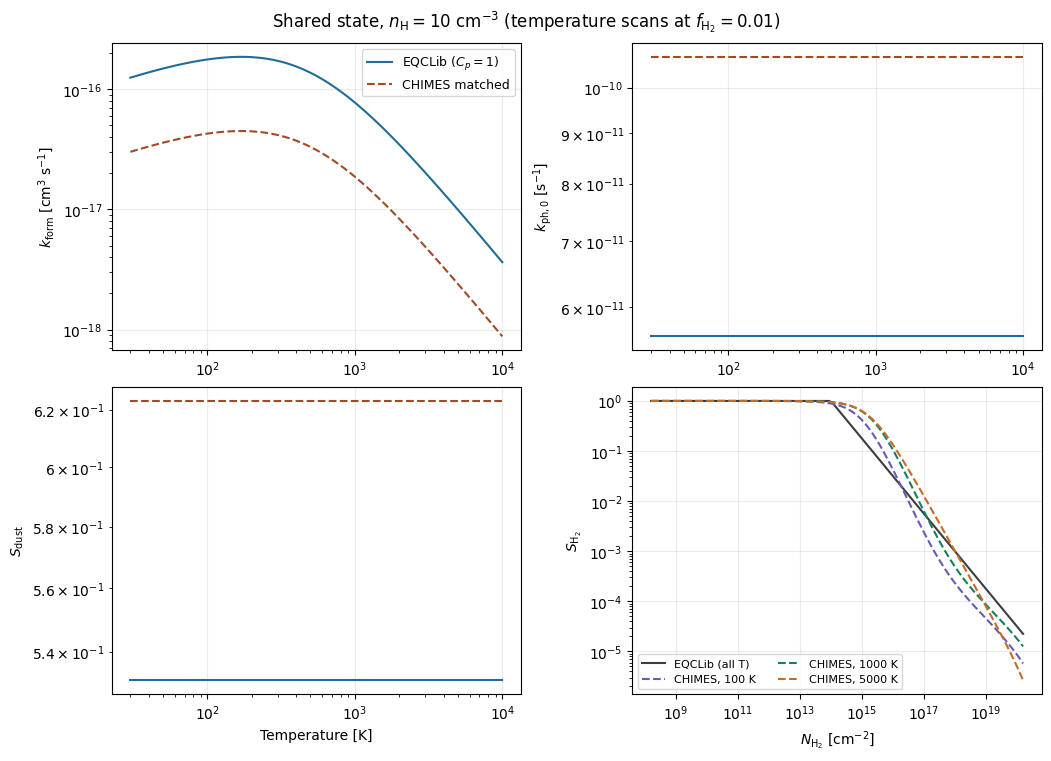

| T [K] | 生成係数比 | 遮蔽前光解離比 | ダスト減光比 | 自己遮蔽比 | 光解離比 | 回転振動冷却比 | 全損失中の光解離（EQCLib / CHIMES） |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 100 | 4.14 | 0.522 | 0.853 | 4.39 | 1.95 | 1.06 | 100.0% / 99.6% |
| 1000 | 4.14 | 0.522 | 0.853 | 2.16 | 0.959 | 1 | 100.0% / 82.9% |
| 5000 | 4.14 | 0.522 | 0.853 | 1.15 | 0.513 | 1 | 80.4% / 2.4% |

In [2]:
focus_density = 10.0
focus_fraction = 1e-2
diagnostic_temperatures = (100, 1000, 5000)

def fixed_fraction(model, nH, fraction):
    rows = density_slice(shared[model], nH)
    actual = nearest(rows["fH2"], fraction)
    rows = rows[rows["fH2"] == actual]
    return np.sort(rows, order="T"), actual

def fixed_temperature(model, nH, temperature):
    rows = density_slice(shared[model], nH)
    actual = nearest(rows["T"], temperature)
    rows = rows[rows["T"] == actual]
    return np.sort(rows, order="fH2"), actual

fig, axes = plt.subplots(2, 2, figsize=(10.4, 7.5), layout="constrained")
for model in shared:
    rows, f_actual = fixed_fraction(model, focus_density, focus_fraction)
    T = rows["T"]
    model_line(axes[0, 0], T, rows["k_form"], model)
    model_line(axes[0, 1], T, rows["k_photo0"], model)
    model_line(axes[1, 0], T, rows["dust_shield"], model)
axes[0, 0].set(ylabel=r"$k_{\rm form}$ [cm$^3$ s$^{-1}$]", yscale="log")
axes[0, 1].set(ylabel=r"$k_{\rm ph,0}$ [s$^{-1}$]", yscale="log")
axes[1, 0].set(ylabel=r"$S_{\rm dust}$", xlabel="Temperature [K]", yscale="log")
for ax in (axes[0, 0], axes[0, 1], axes[1, 0]):
    ax.set_xscale("log")
    ax.grid(alpha=.25)
axes[0, 0].legend(fontsize=9)

def plot_shielding(model, temperature, color, label):
    rows, actual = fixed_temperature(model, focus_density, temperature)
    column = 0.5*rows["fH2"]*1e20*np.sqrt(focus_density)
    valid = (column > 0) & (rows["self_shield"] > 0)
    axes[1, 1].loglog(column[valid], rows["self_shield"][valid],
                      color=color, ls=models[model][2], label=label.format(actual=actual))

plot_shielding("eqclib", 1000, "0.24", "EQCLib (all T)")
for temperature, color in zip(diagnostic_temperatures, ("#655bbb", "#13805e", "#c66c23")):
    plot_shielding("chimes_matched", temperature, color, "CHIMES, {actual:.0f} K")
axes[1, 1].set(xlabel=r"$N_{\rm H_2}$ [cm$^{-2}$]", ylabel=r"$S_{\rm H_2}$")
axes[1, 1].grid(alpha=.25)
axes[1, 1].legend(fontsize=8, ncol=2)
fig.suptitle(rf"Shared state, $n_{{\rm H}}={focus_density:g}$ cm$^{{-3}}$"
             rf" (temperature scans at $f_{{\rm H_2}}={f_actual:.2g}$)")
show_figure(fig)

rate_rows = []
for temperature in diagnostic_temperatures:
    a, f_actual = fixed_fraction("eqclib", focus_density, focus_fraction)
    b, _ = fixed_fraction("chimes_matched", focus_density, focus_fraction)
    T = nearest(a["T"], temperature)
    ea, cb = a[a["T"] == T][0], b[b["T"] == T][0]
    ratios = [ea[key] / cb[key] for key in ("k_form", "k_photo0", "dust_shield", "self_shield",
                                            "destroy_photo", "cool_h2")]
    rates = [ea["destroy_photo"], ea["destroy_coll"], ea["destroy_other"]]
    other = [cb["destroy_photo"], cb["destroy_coll"], cb["destroy_other"]]
    rate_rows.append([f"{T:.0f}", *[f"{v:.3g}" for v in ratios],
                      f"{rates[0] / sum(rates):.1%} / {other[0] / sum(other):.1%}"])
markdown_table(("T [K]", "生成係数比", "遮蔽前光解離比", "ダスト減光比", "自己遮蔽比",
                "光解離比", "回転振動冷却比", "全損失中の光解離（EQCLib / CHIMES）"), rate_rows)

## 反応フラックスを一項ずつ入れ替えたときの H₂ 分率

共通組成の診断点で、$R_{\rm form,grain}+R_{\rm form,other}=R_{\rm loss,ph}+R_{\rm loss,coll}+R_{\rm loss,other}$ を満たす $f_{\rm H_2}$ を探します。EQCLib のフラックスを出発点とし、表に示す一項だけ CHIMES の値に入れ替えます。光解離を分解して置き換える列では、EQCLib の光解離フラックスに該当因子の CHIMES / EQCLib 比を掛けます。

この試算では H I・H₂ 配分以外の組成と電離度を固定します。「光解離以外の損失」は衝突による解離とその他の反応による損失を足した総フラックスで、生成側は EQCLib の値を使います。平衡解は、分率を増やしたときに生成超過から損失超過へ移る点を分率格子から求めます。複数の根がある場合はすべて示します。

In [3]:
def root_values(x, net, log_x):
    roots = []
    for i in range(len(x)-1):
        x0, x1, f0, f1 = x[i], x[i+1], net[i], net[i+1]
        if not np.all(np.isfinite((f0, f1))) or f0 <= 0 or f1 > 0:
            continue
        a = f0 / (f0 - f1)
        if log_x and x0 > 0:
            roots.append(np.exp((1-a)*np.log(x0) + a*np.log(x1)))
        else:
            roots.append((1-a)*x0 + a*x1)
    return roots

def balance_root(fraction, formation, loss):
    # Normalise by the flux scale before interpolating across the sign change.
    imbalance = ratio(formation-loss, formation+loss)
    return root_values(fraction, imbalance, log_x=True)

def root_text(values):
    return ", ".join(f"{value:.3g}" for value in values) if values else "範囲内で未検出"

cases = []
for nH in densities:
    for temperature in diagnostic_temperatures:
        a, T = fixed_temperature("eqclib", nH, temperature)
        b, _ = fixed_temperature("chimes_matched", nH, temperature)
        if not len(a) or not np.array_equal(a["fH2"], b["fH2"]):
            raise ValueError(f"H₂ fraction grid mismatch at nH={nH}, T={T}")
        f = a["fH2"]
        eq_form = a["form_grain"] + a["form_other"]
        ch_form = b["form_grain"] + b["form_other"]
        eq_nonph = a["destroy_coll"] + a["destroy_other"]
        ch_nonph = b["destroy_coll"] + b["destroy_other"]
        eq_photo = a["destroy_photo"]
        roots = [balance_root(f, eq_form, eq_photo + eq_nonph),
                 balance_root(f, b["form_grain"] + a["form_other"], eq_photo + eq_nonph)]
        for term in ("k_photo0", "dust_shield", "self_shield"):
            roots.append(balance_root(f, eq_form, eq_photo*ratio(b[term], a[term]) + eq_nonph))
        roots.append(balance_root(f, eq_form, eq_photo + ch_nonph))
        roots.append(balance_root(f, ch_form, b["destroy_photo"] + ch_nonph))
        cases.append([f"{nH:g} / {T:.0f}", *map(root_text, roots)])
markdown_table(("nH [cm⁻³] / T [K]", "EQCLib", "粒子上の生成", "遮蔽前光解離",
                "ダスト減光", "自己遮蔽", "光解離以外の損失", "CHIMES"), cases)

| nH [cm⁻³] / T [K] | EQCLib | 粒子上の生成 | 遮蔽前光解離 | ダスト減光 | 自己遮蔽 | 光解離以外の損失 | CHIMES |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 3 / 100 | 0.162 | 0.00112 | 0.0223 | 0.132 | 0.661 | 0.159 | 4.76e-06, 0.0198 |
| 3 / 1000 | 0.0116 | 4.14e-05 | 0.000897 | 0.00828 | 3.86e-05, 0.126 | 0.0103 | 1.45e-06 |
| 3 / 5000 | 3.29e-06 | 3.62e-07 | 7.83e-07 | 2.32e-06 | 1.62e-06 | 2.98e-06 | 1.74e-07 |
| 10 / 100 | 0.815 | 0.382 | 0.667 | 0.788 | 0.951 | 0.808 | 0.55 |
| 10 / 1000 | 0.614 | 0.0722 | 0.356 | 0.557 | 0.765 | 0.182 | 1.3e-05, 0.0224 |
| 10 / 5000 | 0.00457 | 2.62e-05 | 0.000542 | 0.00294 | 1.84e-05 | 8.18e-05 | 7.45e-07 |
| 30 / 100 | 0.973 | 0.891 | 0.95 | 0.965 | 0.994 | 0.97 | 0.92 |
| 30 / 1000 | 0.94 | 0.761 | 0.883 | 0.921 | 0.968 | 0.244 | 0.064 |
| 30 / 5000 | 0.0304 | 0.00455 | 0.0243 | 0.0282 | 0.0345 | 0.000115 | 4.42e-06 |
| 100 / 100 | 0.997 | 0.991 | 0.996 | 0.996 | 0.999 | 0.996 | 0.988 |
| 100 / 1000 | 0.995 | 0.978 | 0.991 | 0.992 | 0.997 | 0.254 | 0.0752 |
| 100 / 5000 | 0.0375 | 0.00879 | 0.0369 | 0.0371 | 0.0379 | 0.00012 | 2.51e-05 |

### 各コードの平衡組成での H₂ 損失

CHIMES の平衡組成で、光解離と直接の衝突解離を除いた反応による **正味の H₂ 損失**を確認します。非光化学反応には宇宙線反応やイオン・分子への変換が含まれます。OH と CH⁺ の欄は、O + H₂ ⇄ OH + H と C⁺ + H₂ ⇄ CH⁺ + H の各反応対の正方向から逆方向を引いた値です。これらは非光化学反応の内訳です。EQCLib の H₂ 化学はダスト生成・光解離・直接衝突解離を扱います。フラックスの単位は分子数 $\mathrm{cm^{-3}\,s^{-1}}$ です。 [EQCLib の H₂ 収支](../../../src/EquilibriumAbundance.c)

In [4]:
sink_rows = []
ch = native["chimes_matched"]
for nH in (10, 30, 100):
    for T in (1000, 3000):
        match = density_slice(ch, nH)
        match = match[match["T"] == T]
        if not len(match):
            continue
        row = match[0]
        other_net = row["destroy_other"] - row["form_other"]
        sink_rows.append([f"{nH:g} / {T:g}", *[f"{v:.3g}" for v in (
            row["form_grain"], row["destroy_photo"], row["destroy_coll"],
            other_net, row["net_oh"], row["net_chplus"],
        )]])
markdown_table(("nH [cm⁻³] / T [K]", "ダスト生成", "光解離", "直接衝突解離",
                "その他の正味損失", "OH 経路", "CH⁺ 経路"), sink_rows)

| nH [cm⁻³] / T [K] | ダスト生成 | 光解離 | 直接衝突解離 | その他の正味損失 | OH 経路 | CH⁺ 経路 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 10 / 1000 | 1.87e-15 | 1.87e-15 | 1.47e-41 | -9.52e-18 | 1.02e-19 | -2.98e-19 |
| 10 / 3000 | 4.88e-16 | 5.12e-16 | 7.34e-24 | -2.37e-17 | 1.2e-18 | -1.13e-19 |
| 30 / 1000 | 1.52e-14 | 3.08e-15 | 1.19e-36 | 1.21e-14 | 6.48e-15 | 1.45e-15 |
| 30 / 3000 | 4.4e-15 | 4.66e-15 | 7.28e-22 | -2.63e-16 | 5.54e-17 | 2.53e-18 |
| 100 / 1000 | 1.33e-13 | 4.7e-15 | 6.97e-35 | 1.28e-13 | 7.81e-14 | 7.17e-15 |
| 100 / 3000 | 4.87e-14 | 2.94e-15 | 3.3e-18 | 4.57e-14 | 4.01e-14 | 3.28e-15 |

## 回転振動冷却と熱収支

左図は同じ組成での H₂ 1分子あたりの回転振動冷却です。$\Lambda_{\rm H_2,rovib}$ は分子への衝突励起に伴う放射を表します。衝突解離のエネルギー損失は別項です。EQCLib は Glover & Abel の低密度近似を使い、CHIMES は低密度極限と局所熱平衡（LTE）極限を補間します。 [Glover & Abel (2008)](https://arxiv.org/abs/0803.1768) · [Richings et al. (2014), I](https://arxiv.org/abs/1401.4719)

右図は各コードの化学平衡組成で評価した回転振動冷却の全冷却に占める割合です。残りには原子・イオン冷却、分子の衝突解離などが入り、CHIMES の分子ネットワークには CO なども含まれます。

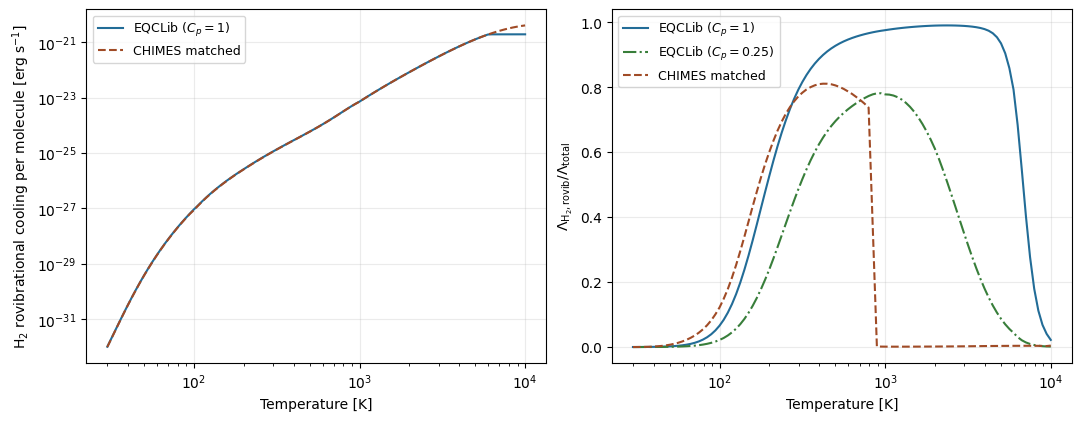

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.7, 4.1), layout="constrained")
for model in shared:
    rows, _ = fixed_fraction(model, focus_density, focus_fraction)
    h2_density = 0.5*focus_density*rows["fH2"]
    model_line(axes[0], rows["T"], ratio(rows["cool_h2"], h2_density), model)
for model in models:
    rows = np.sort(density_slice(native[model], focus_density), order="T")
    model_line(axes[1], rows["T"], ratio(rows["cool_h2"], rows["cool"]), model)
axes[0].set(xscale="log", yscale="log", ylabel=r"H$_2$ rovibrational cooling per molecule [erg s$^{-1}$]")
axes[1].set(xscale="log", ylabel=r"$\Lambda_{\rm H_2,rovib}/\Lambda_{\rm total}$")
for ax in axes:
    ax.set(xlabel="Temperature [K]")
    ax.grid(alpha=.25)
    ax.legend(fontsize=9)
show_figure(fig)

## 化学平衡の H₂ 分率と熱平衡温度

固定温度で化学平衡を求めてから全加熱率 $\Gamma$ と全冷却率 $\Lambda$ を評価します。熱平衡温度は、密度を固定して $\Gamma-\Lambda$ が正から負へ変わる温度を対数温度格子で補間した値です。熱平衡の変化には、H₂ 放射冷却のほか、H₂ が変化したことによる H I・金属イオン量や加熱率の変化も含まれます。EQCLib は CO 生成をオフにしています。CHIMES matched は CO を含む分子ネットワークを使います。

CHIMES の固定温度平衡は 2 点で未収束でした（nH=10 cm⁻³, T=841 K、nH=30 cm⁻³, T=2661 K）。

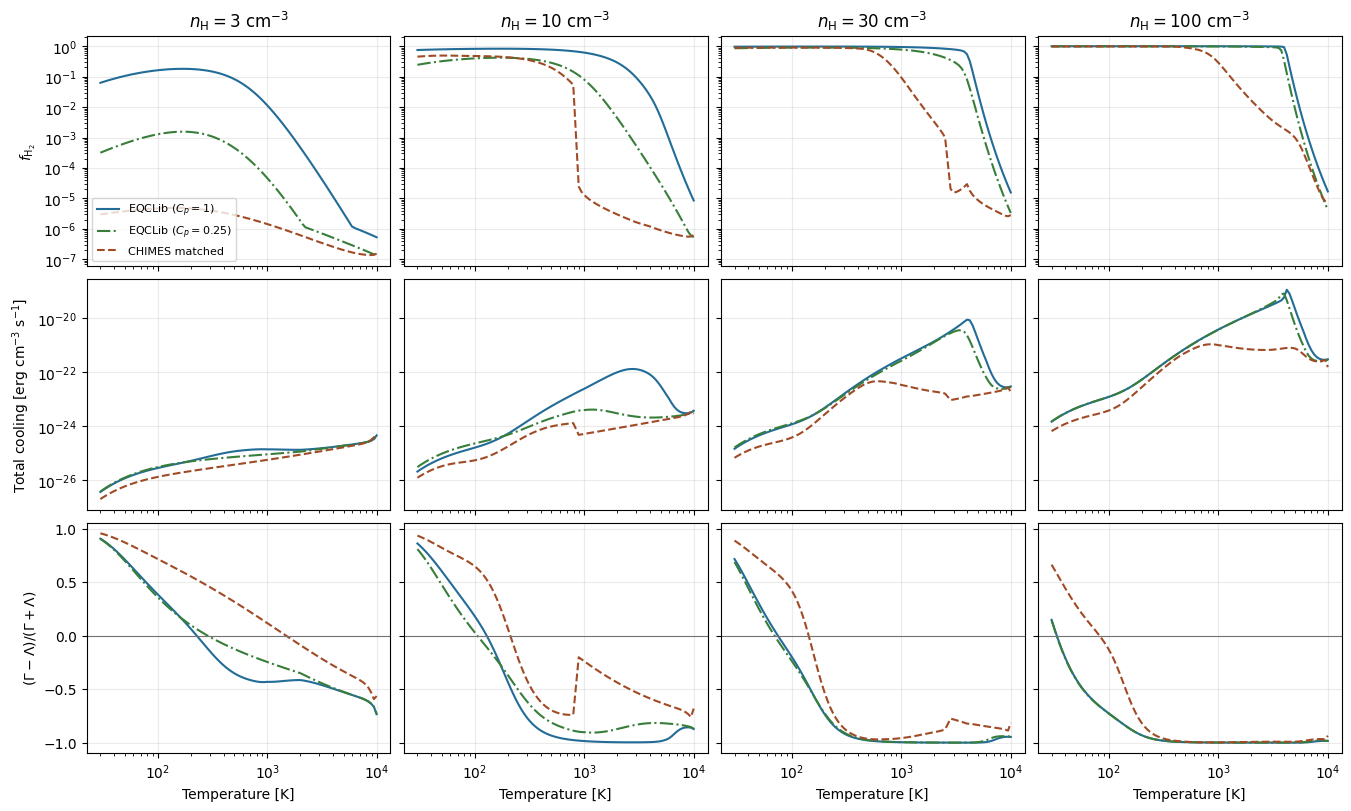

| nH [cm⁻³] | EQCLib [K] | EQCLib Cp=0.25 [K] | CHIMES matched [K] |
| --- | ---: | ---: | ---: |
| 3 | 227.5 | 286.4 | 1491.1 |
| 10 | 128.6 | 105.8 | 211.4 |
| 30 | 74.7 | 69.6 | 142.6 |
| 100 | 33.5 | 33.3 | 82.1 |

In [6]:
unsolved = equilibrium["chimes_matched"][
    (equilibrium["chimes_matched"]["sample"] == "native") & (equilibrium["chimes_matched"]["status"] != 0)]
if len(unsolved):
    points = "、".join(f"nH={r['nH']:g} cm⁻³, T={r['T']:.0f} K" for r in unsolved)
    display(Markdown(f"CHIMES の固定温度平衡は {len(unsolved)} 点で未収束でした（{points}）。"))

fig, axes = plt.subplots(3, len(densities), figsize=(13.4, 8.0),
                         sharex=True, sharey="row", layout="constrained")
thermal_rows = []
for idx, nH in enumerate(densities):
    root_row = [f"{nH:g}"]
    for model in models:
        rows = np.sort(density_slice(native[model], nH), order="T")
        if len(rows) < 2:
            root_row.append("データ不足")
            continue
        T = rows["T"]
        normalized_heat = ratio(rows["heat"] - rows["cool"], rows["heat"] + rows["cool"])
        model_line(axes[0, idx], T, rows["fH2"], model)
        model_line(axes[1, idx], T, rows["cool"], model)
        model_line(axes[2, idx], T, normalized_heat, model)
        roots = root_values(T, normalized_heat, log_x=True)
        root_row.append(", ".join(f"{value:.1f}" for value in roots) if roots else "範囲内で未検出")
    thermal_rows.append(root_row)
    axes[0, idx].set_title(rf"$n_{{\rm H}}={nH:g}$ cm$^{{-3}}$")
    axes[2, idx].axhline(0, color="0.45", lw=.8)
    axes[2, idx].set(xlabel="Temperature [K]")
for ax in axes.flat:
    ax.set_xscale("log")
    ax.grid(alpha=.25)
axes[0, 0].set(yscale="log", ylabel=r"$f_{\rm H_2}$")
axes[1, 0].set(yscale="log", ylabel=r"Total cooling [erg cm$^{-3}$ s$^{-1}$]")
axes[2, 0].set(ylabel=r"$(\Gamma-\Lambda)/(\Gamma+\Lambda)$")
axes[0, 0].legend(fontsize=8, loc="lower left")
show_figure(fig)
markdown_table(("nH [cm⁻³]", "EQCLib [K]", "EQCLib Cp=0.25 [K]", "CHIMES matched [K]"), thermal_rows)

## 回転振動冷却の処方だけを置き換える試算

EQCLib 平衡組成、加熱率、H₂ 回転振動以外の冷却率を固定し、回転振動冷却だけに共通組成上の CHIMES / EQCLib 比を掛けます。比は同じ温度・密度で、各温度の EQCLib 平衡 H₂ 分率に対して分率格子で線形補間します。電子数密度と衝突相手の数密度は共通組成での診断値です。

時間の目安は、温度ごとの EQCLib 平衡内部エネルギー密度 $E$ を使い、$dE/dt=\Gamma-\Lambda$ を温度格子上で台形積分して求めます。正味冷却がゼロをまたぐ直前の格子点までを示します。

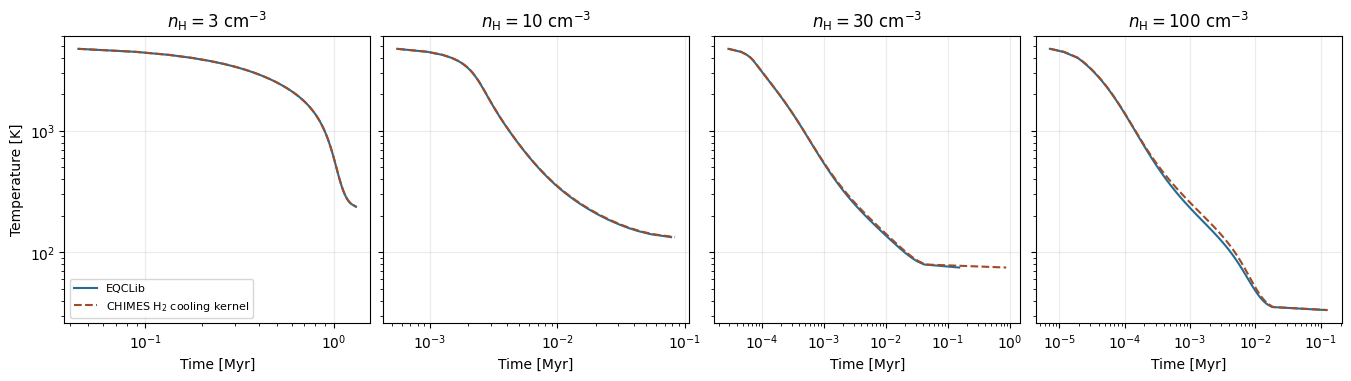

| nH [cm⁻³] | EQCLib 熱平衡 [K] | EQCLib 1000 K 到達 [Myr] | 冷却項置換後の熱平衡 [K] | 冷却項置換後の1000 K 到達 [Myr] |
| --- | ---: | ---: | ---: | ---: |
| 3 | 227.5 | 0.896 | 227.7 | 0.896 |
| 10 | 128.6 | 0.00418 | 129.3 | 0.00419 |
| 30 | 74.7 | 0.000471 | 75.0 | 0.000474 |
| 100 | 33.5 | 0.000145 | 33.5 | 0.000146 |

In [7]:
def cooling_kernel_ratio(nH, T, fraction):
    a = density_slice(shared["eqclib"], nH)
    b = density_slice(shared["chimes_matched"], nH)
    a = np.sort(a[a["T"] == T], order="fH2")
    b = np.sort(b[b["T"] == T], order="fH2")
    if not np.array_equal(a["fH2"], b["fH2"]):
        raise ValueError(f"H₂ fraction grid mismatch at nH={nH}, T={T}")
    kernel = ratio(b["cool_h2"], a["cool_h2"])
    valid = np.isfinite(kernel) & (kernel > 0)
    if not np.any(valid):
        return np.nan
    return np.interp(fraction, a["fH2"][valid], kernel[valid])

def crossing_time(t, T, threshold):
    for i in range(len(T)-1):
        if T[i] > threshold >= T[i+1] and t[i+1] > 0:
            a = np.log(T[i]/threshold) / np.log(T[i]/T[i+1])
            if t[i] <= 0:
                return a*t[i+1]
            return np.exp((1-a)*np.log(t[i]) + a*np.log(t[i+1]))
    return np.nan

def integrated_curve(rows, cooling, initial=5000.0):
    T = rows["T"]
    net_cool = cooling - rows["heat"]
    valid = np.isfinite(net_cool) & np.isfinite(rows["energy"])
    T, net_cool, energy = T[valid], net_cool[valid], rows["energy"][valid]
    Ts = np.r_[initial, T[T < initial][::-1]]
    net_cool = np.interp(Ts, T, net_cool)
    energy = np.interp(Ts, T, energy)
    elapsed = [0.]
    for i in range(1, len(Ts)):
        if min(net_cool[i], net_cool[i-1]) <= 0 or energy[i] >= energy[i-1]:
            break
        dt = (energy[i-1] - energy[i])*(1/net_cool[i] + 1/net_cool[i-1])/2
        elapsed.append(elapsed[-1] + dt/3.15576e7)
    return np.asarray(elapsed), Ts[:len(elapsed)]

fig, axes = plt.subplots(1, len(densities), figsize=(13.4, 3.7),
                         sharey=True, layout="constrained")
sensitivity = []
for ax, nH in zip(axes, densities):
    rows = np.sort(density_slice(native["eqclib"], nH), order="T")
    kernels = np.asarray([cooling_kernel_ratio(nH, r["T"], r["fH2"]) for r in rows])
    modified = rows["cool"] + rows["cool_h2"]*(kernels - 1)
    row = [f"{nH:g}"]
    for name, cooling, color, ls in (
        ("EQCLib", rows["cool"], "#226c97", "-"),
        ("CHIMES H$_2$ cooling kernel", modified, "#a04b26", "--"),
    ):
        roots = root_values(rows["T"], ratio(rows["heat"]-cooling, rows["heat"]+cooling), log_x=True)
        row.append(", ".join(f"{value:.1f}" for value in roots) if roots else "範囲内で未検出")
        times, T = integrated_curve(rows, cooling)
        ax.loglog(times[1:]/1e6, T[1:], color=color, ls=ls, label=name)
        crossing = crossing_time(times, T, 1000.)
        row.append(f"{crossing/1e6:.3g}" if np.isfinite(crossing) else "–")
    sensitivity.append(row)
    ax.set(title=rf"$n_{{\rm H}}={nH:g}$ cm$^{{-3}}$", xlabel="Time [Myr]")
    ax.grid(alpha=.25)
axes[0].set_ylabel("Temperature [K]")
axes[0].legend(fontsize=8)
show_figure(fig)

markdown_table(("nH [cm⁻³]", "EQCLib 熱平衡 [K]", "EQCLib 1000 K 到達 [Myr]",
                "冷却項置換後の熱平衡 [K]", "冷却項置換後の1000 K 到達 [Myr]"), sensitivity)

## 等積冷却履歴

同じ初期温度・密度からエネルギーを更新し、H₂ 分率も追います。化学平衡組成から開始し、EQCLib の平衡更新と非平衡更新、CHIMES の非平衡更新を図示します。平衡更新は各時刻で化学平衡に達した組成を使い、非平衡更新では H₂ が反応時間に従って増減します。CHIMES は各更新の開始時の組成から遮蔽柱密度を決めます。

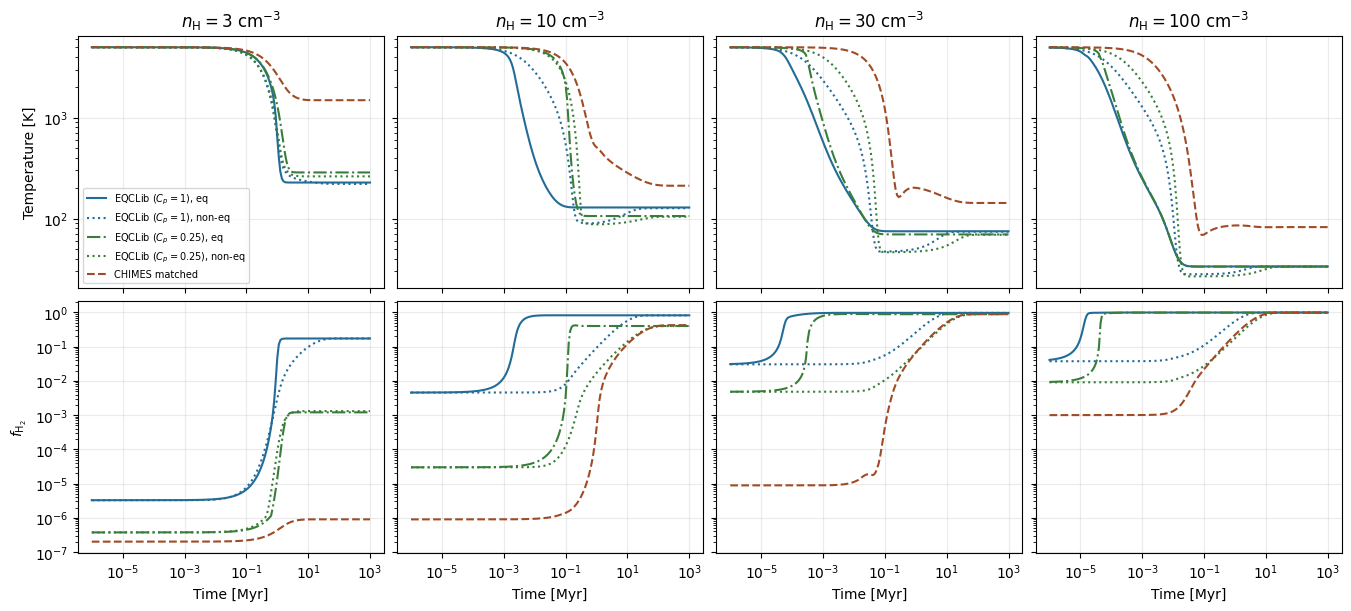

| nH [cm⁻³] | 初期 T [K] | 方式 | 初期 H₂ 分率 | 1000 K 到達 [Myr] | 最終時刻 [Myr] | 最終 T [K] | 最終 H₂ 分率 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 3 | 5000 | EQCLib (C_p=1), eq | 3.27e-06 | 0.9 | 1e+03 | 227 | 0.174 |
| 3 | 5000 | EQCLib (C_p=1), non-eq | 3.27e-06 | 0.801 | 1e+03 | 220 | 0.175 |
| 3 | 5000 | EQCLib (C_p=0.25), eq | 3.74e-07 | 1.18 | 1e+03 | 286 | 0.00121 |
| 3 | 5000 | EQCLib (C_p=0.25), non-eq | 3.74e-07 | 0.858 | 1e+03 | 262 | 0.00131 |
| 3 | 5000 | CHIMES matched | 2.01e-07 | – | 1e+03 | 1.49e+03 | 9.03e-07 |
| 10 | 5000 | EQCLib (C_p=1), eq | 0.00457 | 0.00438 | 1e+03 | 129 | 0.826 |
| 10 | 5000 | EQCLib (C_p=1), non-eq | 0.00457 | 0.0622 | 1e+03 | 127 | 0.825 |
| 10 | 5000 | EQCLib (C_p=0.25), eq | 2.99e-05 | 0.122 | 1e+03 | 106 | 0.402 |
| 10 | 5000 | EQCLib (C_p=0.25), non-eq | 2.99e-05 | 0.18 | 1e+03 | 104 | 0.401 |
| 10 | 5000 | CHIMES matched | 9e-07 | 0.461 | 1e+03 | 211 | 0.427 |
| 30 | 5000 | EQCLib (C_p=1), eq | 0.0305 | 0.000503 | 1e+03 | 74.7 | 0.972 |
| 30 | 5000 | EQCLib (C_p=1), non-eq | 0.0305 | 0.00631 | 1e+03 | 74 | 0.972 |
| 30 | 5000 | EQCLib (C_p=0.25), eq | 0.00481 | 0.000904 | 1e+03 | 69.6 | 0.889 |
| 30 | 5000 | EQCLib (C_p=0.25), non-eq | 0.00481 | 0.0201 | 1e+03 | 69 | 0.889 |
| 30 | 5000 | CHIMES matched | 8.87e-06 | 0.112 | 1e+03 | 143 | 0.901 |
| 100 | 5000 | EQCLib (C_p=1), eq | 0.0375 | 0.000154 | 1e+03 | 33.5 | 0.997 |
| 100 | 5000 | EQCLib (C_p=1), non-eq | 0.0375 | 0.00163 | 1e+03 | 33.4 | 0.997 |
| 100 | 5000 | EQCLib (C_p=0.25), eq | 0.00911 | 0.000184 | 1e+03 | 33.3 | 0.989 |
| 100 | 5000 | EQCLib (C_p=0.25), non-eq | 0.00911 | 0.00432 | 1e+03 | 33.3 | 0.989 |
| 100 | 5000 | CHIMES matched | 0.001 | 0.017 | 1e+03 | 82.2 | 0.983 |

In [8]:
def history_methods(model, rows):
    available = np.unique(rows["method"]).tolist()
    if model == "chimes_matched":
        return available
    representative = [m for m in available if m == "eqclib_eq" or "1e-4" in m]
    return representative or available[:2]

fig, axes = plt.subplots(2, len(densities), figsize=(13.4, 6.0),
                         sharex=True, sharey="row", layout="constrained")
records = []
for i, nH in enumerate(densities):
    for model in models:
        all_rows = density_slice(history[model], nH)
        for method in history_methods(model, all_rows):
            selected = all_rows[all_rows["method"] == method]
            for initial in np.unique(selected["T0"]):
                rows = np.sort(good(selected[selected["T0"] == initial]), order="t_yr")
                if not len(rows):
                    continue
                label, color, ls = models[model]
                if model != "chimes_matched":
                    chem = "non-eq" if "noneq" in method else "eq"
                    label = f"{label}, {chem}"
                    if chem == "non-eq":
                        ls = ":"
                positive_t = rows["t_yr"] > 0
                for j, key in enumerate(("T", "fH2")):
                    valid = positive_t & (rows[key] > 0)
                    axes[j, i].plot(rows["t_yr"][valid]/1e6, rows[key][valid], label=label,
                                    color=color, ls=ls)
                t_cross = crossing_time(rows["t_yr"], rows["T"], 1000.0)
                records.append([f"{nH:g}", f"{initial:g}", label.replace("$", ""), f"{rows[0]['fH2']:.3g}",
                                f"{t_cross/1e6:.3g}" if np.isfinite(t_cross) else "–",
                                f"{rows[-1]['t_yr']/1e6:.3g}", f"{rows[-1]['T']:.3g}",
                                f"{rows[-1]['fH2']:.3g}"])
    axes[0, i].set_title(rf"$n_{{\rm H}}={nH:g}$ cm$^{{-3}}$")
    axes[1, i].set(xlabel="Time [Myr]")
for ax in axes.flat:
    ax.set(xscale="log", yscale="log")
    ax.grid(alpha=.25)
axes[0, 0].set(ylabel="Temperature [K]")
axes[1, 0].set(ylabel=r"$f_{\rm H_2}$")
axes[0, 0].legend(fontsize=7)
show_figure(fig)

markdown_table(("nH [cm⁻³]", "初期 T [K]", "方式", "初期 H₂ 分率", "1000 K 到達 [Myr]",
                "最終時刻 [Myr]", "最終 T [K]", "最終 H₂ 分率"), records)

## この条件での結果

- ダスト生成係数は EQCLib が CHIMES の約 4.14 倍でした。遮蔽前の光解離率はそれぞれ $5.61\times10^{-11}$ と $1.075\times10^{-10}\ {\rm s}^{-1}$ です。自己遮蔽の強さの比は温度と H₂ 柱密度で変わります。$n_{\rm H}=10$、1000 K、$f_{\rm H_2}=0.01$ では、EQCLib の自己遮蔽係数が約 2.16 倍大きく、ダスト減光と合わせた光解離率はほぼ同じでした。CHIMES の平衡分率 $f_{\rm H_2}=1.31\times10^{-5}$ にそろえると、EQCLib / CHIMES 比は自己遮蔽係数で 0.24、全光解離率で 0.11 となります（分率格子から補間）。平衡を解くと $f_{\rm H_2}$ は EQCLib の 0.617 に対し、CHIMES は $1.31\times10^{-5}$ です。ここでは生成係数を合わせただけでも分率は 0.080 に減りますが、差が残ります。
- 高密度の暖かい側では光解離以外の損失も効きます。$n_{\rm H}=100$、1000 K の CHIMES では、OH 経路の正味損失は $7.81\times10^{-14}\ {\rm cm^{-3}\,s^{-1}}$ で、光解離の約 17 倍です。直接の衝突解離は両コードで小さい寄与です。温度と H₂ 柱密度の変化を介して、遮蔽と反応フラックスは結合しています。
- $n_{\rm H}=10$、1000 K では、同じ組成で計算した H₂ 回転振動冷却率はほぼ同じでした。平衡組成を使うと EQCLib の全冷却率は約 47 倍に増え、その約 98% を H₂ 回転振動冷却が占めます。回転振動冷却の処方だけを置き換えた試算では、どの密度でも EQCLib の熱平衡温度の変化は 1 K 未満でした。$n_{\rm H}=100$、100 K では、両コードの $f_{\rm H_2}$ は約 1 ですが、全冷却率はなお約 3.2 倍異なり、差の大半は H₂ 回転振動以外の項にあります。
- $n_{\rm H}=10$ で 5000 K から 1000 K まで冷える時間は EQCLib 平衡の標準設定で 0.0044 Myr、生成係数を下げると 0.12 Myr、CHIMES で 0.46 Myr です。EQCLib の非平衡更新ではそれぞれ 0.062、0.18 Myr でした。形成の時間遅れと生成係数の両方が、冷却履歴の差に効いています。

## 原論文に合わせた H₂ 処方の再評価

旧処方、3種類の単独変更、生成と自己遮蔽を更新した現行処方、現行処方に B87 の光解離係数を適用した場合を、同じ元素組成の CHIMES matched と比較します。各単独変更は旧処方を出発点とし、クランピング係数は EQCLib の全版で $C_p=1$ です。

$n_{\rm H}=3,10,30,100\ {\rm cm^{-3}}$、$G_0=1.7$ Habing、ダスト温度 10 K、柱密度、宇宙線電離率は前半と共通です。CHIMES の B87 スペクトルでは EUV を除き、乱流ドップラー幅は EQCLib の 3 km/s に合わせます（前半の CHIMES は 7.1 km/s）。

- **ダスト上の生成** — Glover & Jappsen（表3の反応60）に合わせ、係数の規格化を $3.0\times10^{-17}$ から $3.0\times10^{-18}\ {\rm cm^3\,s^{-1}}$ にします。両式で同じ $\sqrt{T/{\rm K}}$、ダスト量、付着効率を掛けます。 [Glover & Jappsen (2007), 表3](https://arxiv.org/pdf/0705.0182#page=47)
- **光解離** — Glover & Mac Low の式（29）は Draine 型スペクトルを前提に、波長 1000 Å の強度を Habing 場に対する比 $\chi$ で表し、$k_{\rm ph,0}=3.3\times10^{-11}\chi\ {\rm s^{-1}}$ とします。現行 EQCLib はこの係数と、式（31、34）のダスト減光を採用します。B87 の感度試験では、同じ $G_0$ で測った CHIMES の遮蔽前の光解離に合う係数 $6.32391\times10^{-11}\ {\rm s^{-1}}$（$G_0=1$）を使います。 [Glover & Mac Low (2007), 式29、31〜34](https://arxiv.org/pdf/astro-ph/0605120#page=13)
- **自己遮蔽** — Draine & Bertoldi の式（37）を使い、旧処方の式（36）の区分べき乗近似と比較します。$b$ は H₂ の熱ドップラー幅と 3 km/s の乱流成分を二乗和で合わせます。$x=N_{\rm H_2}/(5\times10^{14}\ {\rm cm^{-2}})$、$b_5=b/(1\ {\rm km/s})$ とおくと、式（37）は
  $S_{\rm H_2}=0.965(1+x/b_5)^{-2}+0.035(1+x)^{-1/2}\exp[-8.5\times10^{-4}\sqrt{1+x}]$
  です。CHIMES の自己遮蔽は温度・H₂ 柱密度・ドップラー幅に依存する別の処方です。 [Draine & Bertoldi (1996), 式36〜37](https://arxiv.org/pdf/astro-ph/9603032#page=12) · [Richings et al. (2014), §3.2](https://arxiv.org/pdf/1403.6155#page=6)

自己遮蔽のため、同じ温度と密度に複数の H₂ 化学平衡が存在する場合があります。固定温度の各点は原子的な初期状態から解きます。現行の自己遮蔽処方では、H₂ がゼロなら自己遮蔽を除いた反応収支から初期分率を推定します。許容誤差が厳しくニュートン法を省く場合も同じ推定値を使います。等積冷却では、前の状態の H₂ 分率を初期推定値とし、分率が増える向きに損失と生成の比が増える安定な根を追います。以下の熱平衡温度は、固定温度走査で到達した化学平衡の分枝に対する値です。

再計算はリポジトリのルートで実行します。 [比較手順](README.md)

```bash
bash test/chimes/shielded/run_h2_prescription_comparison.sh
```

以下のセルは `test/out/chimes/shielded/h2_prescription/` の CSV を読みます。

In [9]:
prescription_data = repo / "test/out/chimes/shielded/h2_prescription"
prescriptions = {
    "legacy": ("Legacy EQCLib", "#727272", "-"),
    "formation": ("Formation only", "#228063", "--"),
    "photodissociation": ("B87 rate only", "#8063ad", "--"),
    "shielding": ("Self-shielding only", "#cd781d", "-."),
    "revised": ("Revised EQCLib", "#236aa1", "-"),
    "revised_b87": ("Revised + B87 rate", "#368ca5", "--"),
    "chimes_matched": ("CHIMES matched", "#ae4030", ":"),
}
prescription_names_ja = {
    "legacy": "旧処方",
    "formation": "生成のみ",
    "photodissociation": "光解離のみ（B87 係数）",
    "shielding": "自己遮蔽のみ",
    "revised": "現行",
    "revised_b87": "現行＋B87 係数",
    "chimes_matched": "CHIMES matched",
}

def read_prescription_csv(filename):
    path = prescription_data / filename
    if not path.is_file():
        raise FileNotFoundError(f"{path} がありません。上記のスクリプトで計算してください。")
    return np.atleast_1d(np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8"))

revision_grid = {}
revision_history = {}
for name in prescriptions:
    fixed_t = read_prescription_csv(f"eq_{name}.csv")
    revision_grid[name] = fixed_t[fixed_t["sample"] == "native"]
    revision_history[name] = read_prescription_csv(f"cooling_{name}.csv")
revision_densities = np.unique(revision_grid["legacy"]["nH"])

def prescription_line(axis, x, y, name):
    label, color, ls = prescriptions[name]
    axis.plot(x, y, color=color, ls=ls, lw=2.1 if name == "revised" else 1.3, label=label)

def display_value(value, fmt=".3g"):
    return format(value, fmt) if np.isfinite(value) else "—"


### 固定温度での H₂ 分率と冷却率

分率は $f_{\rm H_2}=2n(\mathrm{H_2})/n_{\rm H}$、冷却率は単位体積あたりの全冷却です。各コードは自身の化学平衡組成を使います。表では 1000 K の絶対値と CHIMES に対する全冷却率比を示します。未収束点では曲線を途切れさせます。絶対対数差の中央値は、全版が成功し分率・冷却率が正の共通格子点で $\lvert\log_{10}(\mathrm{EQCLib}/\mathrm{CHIMES})\rvert$ を求めて集計します。

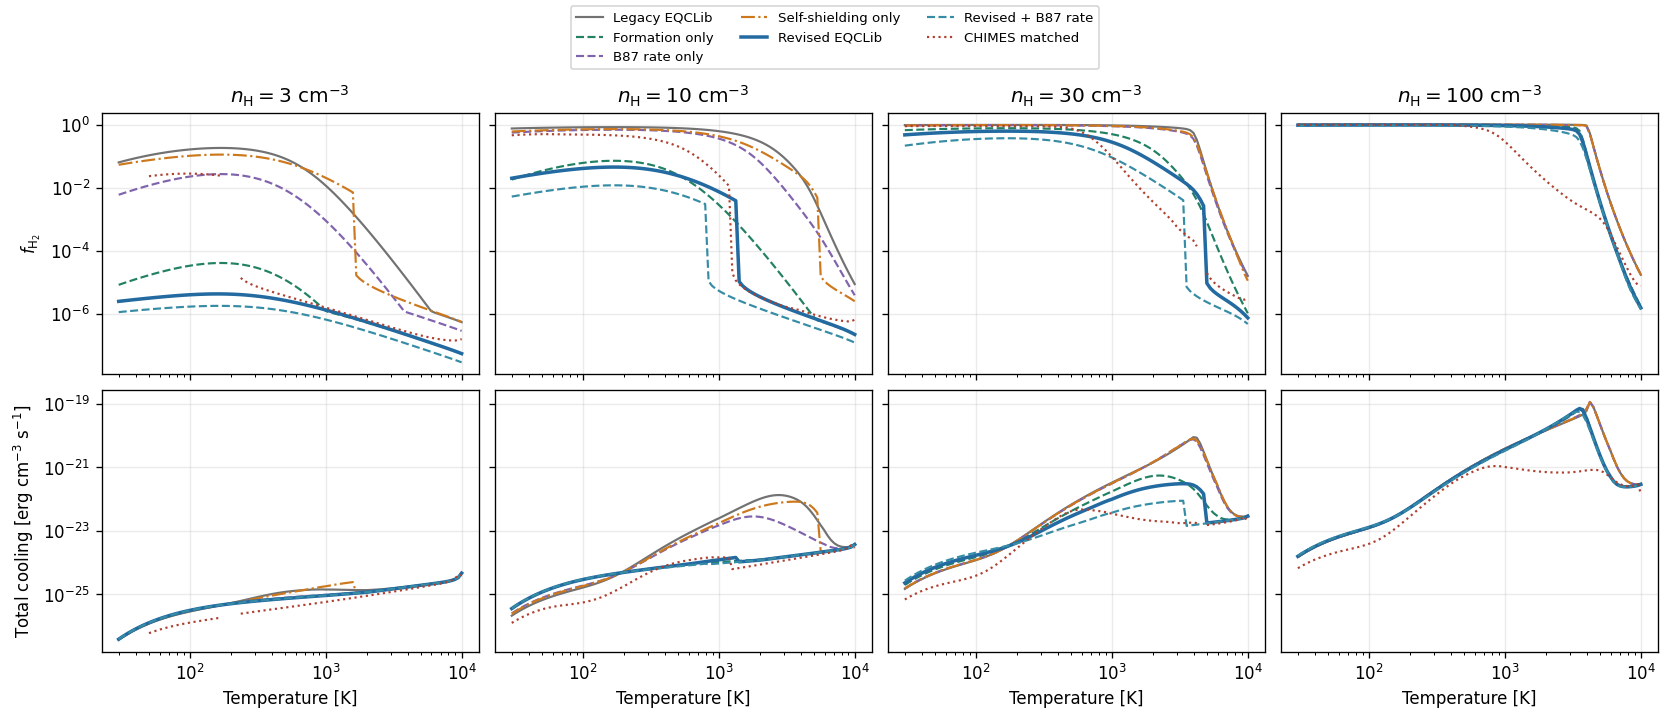

| nH [cm⁻³] | 処方 | H₂ 分率 | 全冷却率 [erg cm⁻³ s⁻¹] | 全冷却率 / CHIMES |
| --- | ---: | ---: | ---: | ---: |
| 3 | 旧処方 | 0.0115 | 1.42e-25 | 2.45 |
| 3 | 生成のみ | 1.21e-06 | 9.23e-26 | 1.6 |
| 3 | 光解離のみ（B87 係数） | 0.000893 | 9.61e-26 | 1.66 |
| 3 | 自己遮蔽のみ | 0.0204 | 1.79e-25 | 3.11 |
| 3 | 現行 | 1.3e-06 | 9.23e-26 | 1.6 |
| 3 | 現行＋B87 係数 | 6.43e-07 | 9.23e-26 | 1.6 |
| 3 | CHIMES matched | 1.54e-06 | 5.77e-26 | 1 |
| 10 | 旧処方 | 0.617 | 2.47e-23 | 17 |
| 10 | 生成のみ | 0.00283 | 1.05e-24 | 0.717 |
| 10 | 光解離のみ（B87 係数） | 0.359 | 1.48e-23 | 10.1 |
| 10 | 自己遮蔽のみ | 0.426 | 1.74e-23 | 11.9 |
| 10 | 現行 | 0.00736 | 1.22e-24 | 0.837 |
| 10 | 現行＋B87 係数 | 5.29e-06 | 9.37e-25 | 0.642 |
| 10 | CHIMES matched | 0.0246 | 1.46e-24 | 1 |
| 30 | 旧処方 | 0.941 | 3.29e-22 | 9.51 |
| 30 | 生成のみ | 0.496 | 1.73e-22 | 5 |
| 30 | 光解離のみ（B87 係数） | 0.888 | 3.1e-22 | 8.96 |
| 30 | 自己遮蔽のみ | 0.9 | 3.14e-22 | 9.09 |
| 30 | 現行 | 0.277 | 9.89e-23 | 2.86 |
| 30 | 現行＋B87 係数 | 0.0899 | 3.72e-23 | 1.08 |
| 30 | CHIMES matched | 0.0945 | 3.46e-23 | 1 |
| 100 | 旧処方 | 0.995 | 3.86e-21 | 3.78 |
| 100 | 生成のみ | 0.954 | 3.7e-21 | 3.61 |
| 100 | 光解離のみ（B87 係数） | 0.991 | 3.85e-21 | 3.76 |
| 100 | 自己遮蔽のみ | 0.993 | 3.85e-21 | 3.77 |
| 100 | 現行 | 0.927 | 3.59e-21 | 3.51 |
| 100 | 現行＋B87 係数 | 0.861 | 3.32e-21 | 3.25 |
| 100 | CHIMES matched | 0.288 | 1.02e-21 | 1 |

| 処方 | 固定温度の成功点数 | 全点数 |
| --- | ---: | ---: |
| 旧処方 | 420 | 420 |
| 生成のみ | 420 | 420 |
| 光解離のみ（B87 係数） | 420 | 420 |
| 自己遮蔽のみ | 420 | 420 |
| 現行 | 420 | 420 |
| 現行＋B87 係数 | 420 | 420 |
| CHIMES matched | 404 | 420 |

| 処方 | 共通格子点 | H₂ 分率の絶対対数差 [dex] | 全冷却率の絶対対数差 [dex] |
| --- | ---: | ---: | ---: |
| 旧処方 | 404 | 0.753 | 0.444 |
| 生成のみ | 404 | 0.415 | 0.309 |
| 光解離のみ（B87 係数） | 404 | 0.511 | 0.404 |
| 自己遮蔽のみ | 404 | 0.632 | 0.446 |
| 現行 | 404 | 0.235 | 0.294 |
| 現行＋B87 係数 | 404 | 0.479 | 0.283 |

In [10]:
fig, axes = plt.subplots(2, len(revision_densities), figsize=(13.8, 5.9),
                         sharex=True, sharey="row", layout="constrained")
for col, nH in enumerate(revision_densities):
    for name, data in revision_grid.items():
        rows = np.sort(density_slice(data, nH), order="T0")
        for axis, key in zip(axes[:, col], ("fH2", "cool")):
            values = np.where((rows["status"] == 0) & (rows[key] > 0), rows[key], np.nan)
            prescription_line(axis, rows["T0"], values, name)
    axes[0, col].set_title(rf"$n_{{\rm H}}={nH:g}$ cm$^{{-3}}$")
    axes[1, col].set_xlabel("Temperature [K]")
for axis in axes.flat:
    axis.set(xscale="log", yscale="log")
    axis.grid(alpha=.25)
axes[0, 0].set_ylabel(r"$f_{\rm H_2}$")
axes[1, 0].set_ylabel(r"Total cooling [erg cm$^{-3}$ s$^{-1}$]")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=8)
show_figure(fig)

def fixed_state(rows, nH, temperature):
    matches = good(density_slice(rows, nH))
    return matches[np.isclose(matches["T0"], temperature, atol=0, rtol=1e-9)]

at_1000_k = []
for nH in revision_densities:
    ch = fixed_state(revision_grid["chimes_matched"], nH, 1000.)
    ref_cooling = ch["cool"][0] if len(ch) else np.nan
    for name, data in revision_grid.items():
        cell = fixed_state(data, nH, 1000.)
        if not len(cell):
            continue
        row = cell[0]
        values = (row["fH2"], row["cool"], row["cool"]/ref_cooling if ref_cooling > 0 else np.nan)
        at_1000_k.append((f"{nH:g}", prescription_names_ja[name], *map(display_value, values)))
markdown_table(("nH [cm⁻³]", "処方", "H₂ 分率", "全冷却率 [erg cm⁻³ s⁻¹]", "全冷却率 / CHIMES"),
               at_1000_k)
markdown_table(("処方", "固定温度の成功点数", "全点数"), [
    (prescription_names_ja[name], len(good(rows)), len(rows)) for name, rows in revision_grid.items()
])

native_points = {
    name: {(r["nH"], r["T0"]): r for r in good(data) if r["fH2"] > 0 and r["cool"] > 0}
    for name, data in revision_grid.items()
}
common_points = sorted(set.intersection(*(set(points) for points in native_points.values())))
reference = native_points["chimes_matched"]
revision_errors = {
    name: [np.median([abs(np.log10(points[key][var]/reference[key][var])) for key in common_points])
           for var in ("fH2", "cool")]
    for name, points in native_points.items() if name != "chimes_matched"
}
markdown_table(("処方", "共通格子点", "H₂ 分率の絶対対数差 [dex]", "全冷却率の絶対対数差 [dex]"), [
    (prescription_names_ja[name], len(common_points), *map(display_value, errors))
    for name, errors in revision_errors.items()
])


### 熱平衡温度

等積での加熱率 $\Gamma$ と冷却率 $\Lambda$ の差 $\Gamma-\Lambda$ が、温度上昇とともに正から負へ変わる区間を安定な熱平衡の候補とします。符号変化の前後で、$(\Gamma-\Lambda)/(\Gamma+\Lambda)$ を対数温度に対して線形補間します。未収束点をまたぐ区間は省き、安定な根が複数得られた場合はすべて示します。

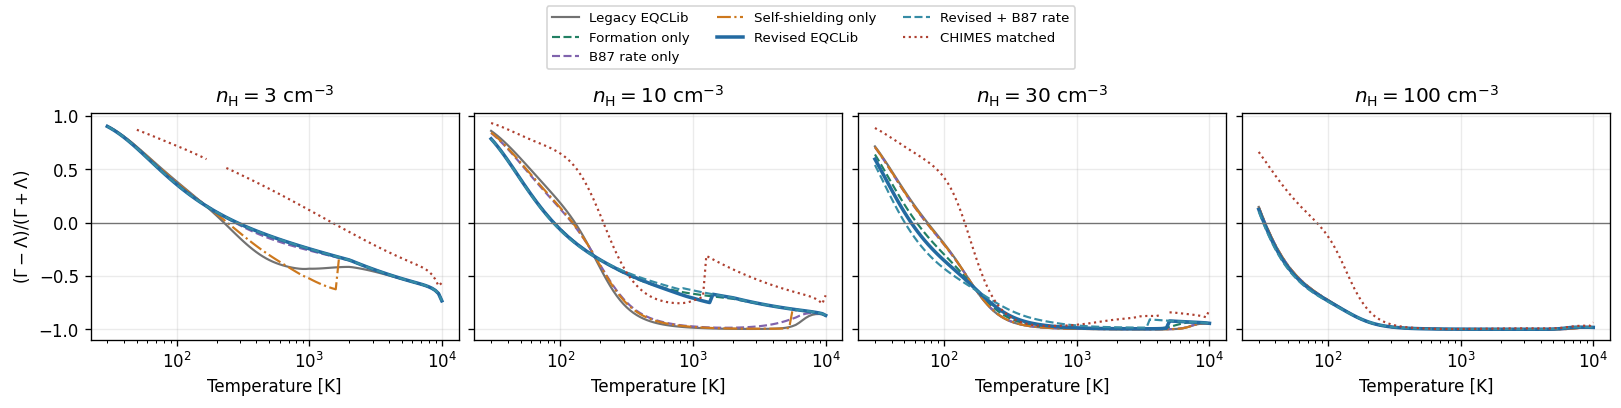

| nH [cm⁻³] | 旧処方 [K] | 生成のみ [K] | 光解離のみ（B87 係数） [K] | 自己遮蔽のみ [K] | 現行 [K] | 現行＋B87 係数 [K] | CHIMES matched [K] |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 3 | 227.5 | 286.2 | 276.0 | 241.5 | 286.2 | 286.2 | 1491.0 |
| 10 | 128.6 | 89.6 | 122.0 | 123.6 | 88.9 | 87.9 | 210.9 |
| 30 | 74.7 | 62.0 | 73.2 | 73.6 | 56.3 | 50.4 | 142.6 |
| 100 | 33.5 | 33.1 | 33.4 | 33.4 | 32.9 | 32.4 | 82.1 |

In [11]:
fig, axes = plt.subplots(1, len(revision_densities), figsize=(13.4, 3.3),
                         sharex=True, sharey=True, layout="constrained")
revision_roots = {}
for axis, nH in zip(axes, revision_densities):
    roots = []
    for name, data in revision_grid.items():
        rows = np.sort(density_slice(data, nH), order="T0")
        net_heat = ratio(rows["heat"]-rows["cool"], rows["heat"]+rows["cool"])
        net_heat[rows["status"] != 0] = np.nan
        prescription_line(axis, rows["T0"], net_heat, name)
        roots.append(root_values(rows["T0"], net_heat, log_x=True))
    revision_roots[nH] = roots
    axis.axhline(0, color="0.45", lw=.8)
    axis.set(title=rf"$n_{{\rm H}}={nH:g}$ cm$^{{-3}}$", xlabel="Temperature [K]", xscale="log")
    axis.grid(alpha=.25)
axes[0].set_ylabel(r"$(\Gamma-\Lambda)/(\Gamma+\Lambda)$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=8)
show_figure(fig)

root_header = ("nH [cm⁻³]", *(f"{name} [K]" for name in prescription_names_ja.values()))
markdown_table(root_header, [
    (f"{nH:g}", *(", ".join(f"{value:.1f}" for value in roots) or "—"
                  for roots in revision_roots[nH]))
    for nH in revision_densities
])


### 等積冷却履歴

同じ密度・5000 K から、各コードがその温度で求めた化学平衡組成を初期値として熱と組成を更新します。EQCLib は平衡モード、CHIMES は非平衡の反応網で時間発展させます。表の到達時刻は、最初に 1000 K を下回る区間の補間値です。更新に失敗した履歴は、その直前までを図示します。EQCLib の非平衡モード（許容誤差 $10^{-4}$）でも到達時刻を集計します。

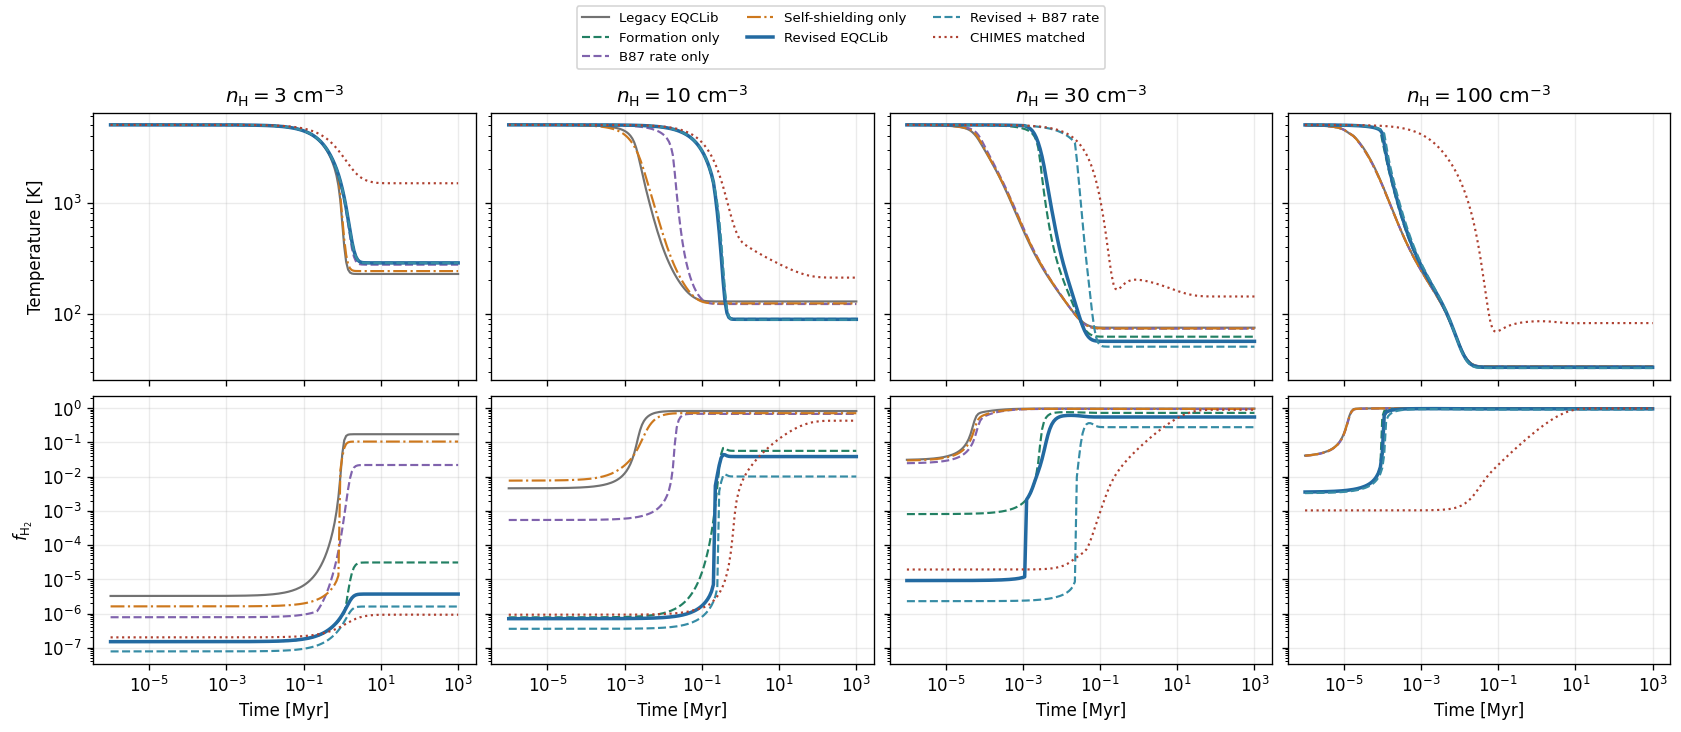

| nH [cm⁻³] | 旧処方 [Myr] | 生成のみ [Myr] | 光解離のみ（B87 係数） [Myr] | 自己遮蔽のみ [Myr] | 現行 [Myr] | 現行＋B87 係数 [Myr] | CHIMES matched [Myr] |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 3 | 0.9 | 1.18 | 1.15 | 0.921 | 1.18 | 1.19 | — |
| 10 | 0.00438 | 0.237 | 0.0236 | 0.00558 | 0.235 | 0.249 | 0.46 |
| 30 | 0.000503 | 0.00386 | 0.000538 | 0.000522 | 0.00522 | 0.0317 | 0.105 |
| 100 | 0.000154 | 0.000242 | 0.000152 | 0.000153 | 0.000254 | 0.000278 | 0.0169 |

図示した 28 本すべてが 10 億年まで進みました。

非平衡モードで 1000 K に達する時刻も比較します。

| nH [cm⁻³] | 旧処方 [Myr] | 生成のみ [Myr] | 光解離のみ（B87 係数） [Myr] | 自己遮蔽のみ [Myr] | 現行 [Myr] | 現行＋B87 係数 [Myr] | CHIMES matched [Myr] |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 3 | 0.801 | 0.858 | 0.847 | 0.841 | 0.858 | 0.859 | — |
| 10 | 0.0622 | 0.189 | 0.128 | 0.0475 | 0.19 | 0.19 | 0.46 |
| 30 | 0.00631 | 0.0396 | 0.00745 | 0.00651 | 0.0583 | 0.0591 | 0.105 |
| 100 | 0.00163 | 0.00712 | 0.00165 | 0.00164 | 0.00708 | 0.0073 | 0.0169 |

In [12]:
main_revision_history = {}
for name, data in revision_history.items():
    methods = np.unique(data["method"])
    method = methods[0] if name == "chimes_matched" else "eqclib_eq"
    selection = data[data["method"] == method]
    if not len(selection):
        raise ValueError(f"{name}: 冷却履歴に {method} がありません。")
    main_revision_history[name] = selection

fig, axes = plt.subplots(2, len(revision_densities), figsize=(13.9, 6.0),
                         sharex=True, sharey="row", layout="constrained")
times_to_1000 = []
history_status = []
for col, nH in enumerate(revision_densities):
    crossings = [f"{nH:g}"]
    for name, data in main_revision_history.items():
        history_rows = np.sort(density_slice(data, nH), order="t_yr")
        successful = good(history_rows)
        if not len(successful):
            crossings.append("—")
            history_status.append((f"{nH:g}", prescription_names_ja[name], "初期化失敗"))
            continue
        for axis, key in zip(axes[:, col], ("T", "fH2")):
            draw = (successful["t_yr"] > 0) & (successful[key] > 0)
            prescription_line(axis, successful["t_yr"][draw]/1e6, successful[key][draw], name)
        crossing = crossing_time(successful["t_yr"], successful["T"], 1000.)
        end_time = successful["t_yr"][-1]
        crossings.append(display_value(crossing/1e6))
        if end_time < 1e9 or len(successful) != len(history_rows):
            history_status.append((f"{nH:g}", prescription_names_ja[name], f"{end_time/1e6:.3g} Myr"))
    times_to_1000.append(crossings)
    axes[0, col].set_title(rf"$n_{{\rm H}}={nH:g}$ cm$^{{-3}}$")
    axes[1, col].set_xlabel("Time [Myr]")
for axis in axes.flat:
    axis.set(xscale="log", yscale="log")
    axis.grid(alpha=.25)
axes[0, 0].set_ylabel("Temperature [K]")
axes[1, 0].set_ylabel(r"$f_{\rm H_2}$")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=8)
show_figure(fig)

history_header = ("nH [cm⁻³]", *(f"{name} [Myr]" for name in prescription_names_ja.values()))
markdown_table(history_header, times_to_1000)
if history_status:
    markdown_table(("nH [cm⁻³]", "処方", "最終成功時刻"), history_status)
else:
    display(Markdown(f"図示した {len(revision_densities)*len(prescriptions)} 本すべてが 10 億年まで進みました。"))

non_equilibrium_crossings = []
for nH in revision_densities:
    row = [f"{nH:g}"]
    for name, data in revision_history.items():
        target = density_slice(data, nH)
        if name != "chimes_matched":
            target = target[target["method"] == "eqclib_noneq_1e-4"]
        successful = np.sort(good(target), order="t_yr")
        time = crossing_time(successful["t_yr"], successful["T"], 1000.) if len(successful) else np.nan
        row.append(display_value(time/1e6))
    non_equilibrium_crossings.append(row)
display(Markdown("非平衡モードで 1000 K に達する時刻も比較します。"))
markdown_table(history_header, non_equilibrium_crossings)


### 平衡モードの CPU 時間

単一コアで SPH のクーラン刻みを使い、同じ物理条件で初期平衡を求めた後の1セル更新を計測します。各条件の代表値は反復計測の CPU 時間の中央値です。各粒子質量で、全 EQCLib 版かつ全パスで成功した共通条件に絞ります。各パスで代表値を合計し、同じパスの旧処方に対する比を求めます。表の相対変化はペア比から求めた中央値と最小・最大です。変更に伴う反応率評価のコストと計算が辿る状態の変化が、どちらも時間に含まれます。

In [13]:
timing_data = read_prescription_csv("timing.csv")
eq_versions = [name for name in prescriptions if name != "chimes_matched"]

def timing_values(rows, name, run):
    selected = rows[(rows["variant"] == name) & (rows["pass"] == run)]
    passed = selected[(selected["seed_status"] == 0) & (selected["status"] == 0)
                      & np.isfinite(selected["cpu_us_median"]) & (selected["cpu_us_median"] > 0)]
    values = {(r["nH"], r["T0"], r["dt_yr"]): r["cpu_us_median"] for r in passed}
    if len(passed) != len(values):
        raise ValueError(f"{name}: タイミングの条件が重複しています。")
    return values

timing_rows = []
chimes_comparison_rows = []
for mass in np.unique(timing_data["mass_msun"]):
    rows = timing_data[timing_data["mass_msun"] == mass]
    passes = np.unique(rows["pass"][rows["variant"] == "legacy"])
    eq_times = {name: [timing_values(rows, name, run) for run in passes] for name in eq_versions}
    common = set.intersection(*(set(t) for runs in eq_times.values() for t in runs))
    if not common:
        raise ValueError(f"{mass:g} Msun: EQCLib 各版と全パスに共通する成功点がありません。")
    pair_means = {name: np.array([np.mean([t[key] for key in common]) for t in runs])
                  for name, runs in eq_times.items()}
    attempted = len(rows[(rows["variant"] == "legacy") & (rows["pass"] == passes[0])])
    for name, means in pair_means.items():
        relative = 100*(means/pair_means["legacy"] - 1)
        changes = [f"{value:+.1f}%" for value in (np.median(relative), np.min(relative), np.max(relative))]
        timing_rows.append((f"{mass:g}", prescription_names_ja[name], f"{len(common)} / {attempted}", len(passes),
                            f"{np.median(means):.2f}", changes[0], f"{changes[1]} 〜 {changes[2]}"))
    chimes_passes = np.unique(rows["pass"][rows["variant"] == "chimes_matched"])
    if len(chimes_passes) == 1:
        chimes_times = timing_values(rows, "chimes_matched", chimes_passes[0])
        comparable = common.intersection(chimes_times)
        if comparable:
            chimes_total = sum(chimes_times[key] for key in comparable)
            revised_total = np.median([sum(t[key] for key in comparable) for t in eq_times["revised"]])
            chimes_comparison_rows.append((f"{mass:g}", f"{len(comparable)} / {attempted}",
                                           f"{chimes_total/revised_total:.2f}"))

markdown_table(("粒子質量 [M☉]", "処方", "共通成功セル", "パス数", "平均 CPU [µs/更新] の中央値",
                "旧処方に対する変化", "変化の最小〜最大"), timing_rows)
if chimes_comparison_rows:
    display(Markdown("同じコアで計測した CHIMES の1パスと、現行 EQCLib の合計 CPU 時間のパス中央値を比べます。"))
    markdown_table(("粒子質量 [M☉]", "CHIMES を含めた共通成功セル", "CHIMES / 現行 EQCLib の CPU 比"),
                   chimes_comparison_rows)


| 粒子質量 [M☉] | 処方 | 共通成功セル | パス数 | 平均 CPU [µs/更新] の中央値 | 旧処方に対する変化 | 変化の最小〜最大 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 100 | 旧処方 | 28 / 28 | 7 | 105.14 | +0.0% | +0.0% 〜 +0.0% |
| 100 | 生成のみ | 28 / 28 | 7 | 85.29 | -18.9% | -22.3% 〜 -9.0% |
| 100 | 光解離のみ（B87 係数） | 28 / 28 | 7 | 104.08 | -0.8% | -5.1% 〜 +24.4% |
| 100 | 自己遮蔽のみ | 28 / 28 | 7 | 101.00 | -5.3% | -7.7% 〜 +3.9% |
| 100 | 現行 | 28 / 28 | 7 | 82.78 | -20.2% | -27.8% 〜 -6.8% |
| 100 | 現行＋B87 係数 | 28 / 28 | 7 | 76.79 | -22.9% | -30.2% 〜 -12.9% |
| 10000 | 旧処方 | 28 / 28 | 7 | 120.05 | +0.0% | +0.0% 〜 +0.0% |
| 10000 | 生成のみ | 28 / 28 | 7 | 97.09 | -19.7% | -22.2% 〜 -8.2% |
| 10000 | 光解離のみ（B87 係数） | 28 / 28 | 7 | 113.29 | -5.1% | -9.4% 〜 +20.5% |
| 10000 | 自己遮蔽のみ | 28 / 28 | 7 | 114.54 | -5.1% | -7.4% 〜 +2.3% |
| 10000 | 現行 | 28 / 28 | 7 | 97.48 | -17.1% | -23.7% 〜 -0.7% |
| 10000 | 現行＋B87 係数 | 28 / 28 | 7 | 86.79 | -23.8% | -30.8% 〜 -13.9% |

同じコアで計測した CHIMES の1パスと、現行 EQCLib の合計 CPU 時間のパス中央値を比べます。

| 粒子質量 [M☉] | CHIMES を含めた共通成功セル | CHIMES / 現行 EQCLib の CPU 比 |
| --- | ---: | ---: |
| 100 | 27 / 28 | 35.06 |
| 10000 | 27 / 28 | 35.41 |

### この比較条件での結果

- **固定温度での差** — この計測の共通404点では、生成係数の変更が単独変更の中で H₂ 分率と全冷却率の誤差を最も縮めました。生成と自己遮蔽を更新した現行処方では、H₂ 分率の絶対対数差の中央値が 0.753 → 0.235 dex、全冷却率は 0.444 → 0.294 dex です。現行処方で光解離を B87 の係数に合わせると、全冷却率の差がわずかに縮む一方、分率の差は増えます。
- **温度の時間発展** — $n_{\rm H}=10\ {\rm cm^{-3}}$ の平衡モードでは、5000 K から 1000 K に冷える時間が 0.00438 → 0.235 Myr となり、CHIMES の 0.460 Myr に近づきました。同じ密度の熱平衡温度は 128.6 → 88.9 K で、CHIMES の 210.9 K との差は拡大しました。冷却履歴と熱平衡温度は、反応処方や H₂ 以外の加熱・冷却の影響を異なる形で受けます。
- **高密度側の残差** — $n_{\rm H}=100\ {\rm cm^{-3}}$、1000 K の現行処方の全冷却率は CHIMES の約3.5倍です。前半で確認した OH などを介した H₂ 消費経路の差も、この条件での分率差に寄与します。

CHIMES の乱流ドップラー幅をそろえた本節のデータから、旧処方と現行処方の差を評価します。冷却履歴には反応処方の差に加え、平衡モードで化学組成を即座に平衡へ戻す影響も含まれます。

## 89 K と 211 K を決める加熱・冷却の内訳

水素核数密度 $n_{\rm H}=3,10,30,100\ {\rm cm^{-3}}$ について、前節と同じ H・He・C・O・Si の存在量、入射 $G_0=1.7$ Habing、宇宙線電離率、ダスト温度 10 K、全水素柱密度、乱流ドップラー幅 3 km/s を使います。CHIMES matched は EUV を除いた B87 場、EQCLib は同じ Habing 強度の Draine 型の光解離処方です。旧・現行 EQCLib は H₂ の生成・自己遮蔽処方が異なります。

固定温度で各コードの化学平衡を解いた組成に加え、同じ組成を両コードに入力した診断を使います。後者は H₂、水素イオン、電子、C⁺、O⁰、Si⁺ の分率を与え、H I を水素数保存から求めます。ヘリウムは中性とし、未指定の元素は C⁰・O⁺・Si⁰ にまとめます。CO や OH などの少量成分を省き、残余の Si を Si⁰ にまとめると、CHIMES の光電離加熱などは各コード自身の平衡組成での値と変わり得ます。共通組成は選択した項の処方の照合に使い、熱平衡の計算には各モデル自身の全加熱・冷却を使います。

加熱・冷却率の単位は $\mathrm{erg\,cm^{-3}\,s^{-1}}$ です。H₂ の回転振動冷却と衝突解離冷却を別々に記録し、図表の H₂ 冷却は両者の和です。CHIMES の C⁺・O⁰ 冷却はイオンごとの表から取り出し、低温域では主に [C II] と [O I] の微細構造線に対応します。その他の項には、列挙していない過程を全率から差し引いた残差を含めます。

リポジトリのルートから計算します。 [比較手順](README.md)

```bash
bash test/chimes/shielded/run_thermal_balance_comparison.sh
```

In [14]:
thermal_data = repo / "test/out/chimes/shielded/thermal_balance"
thermal_models = ("legacy", "eqclib", "chimes")
thermal_names = dict(zip(thermal_models, ("旧 EQCLib", "現行 EQCLib", "CHIMES matched")))

def read_thermal_csv(filename):
    path = thermal_data / filename
    if not path.is_file():
        raise FileNotFoundError(f"{path} がありません。上記のスクリプトで計算してください。")
    return np.atleast_1d(np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8"))

thermal_native = {model: read_thermal_csv(f"native_{model}.csv") for model in thermal_models}
thermal_shared = {model: read_thermal_csv(f"shared_{model}.csv") for model in ("eqclib", "chimes")}
thermal_densities = np.unique(thermal_native["eqclib"]["nH"])
thermal_heat_cols = ("heat_pe", "heat_cr", "heat_h2", "heat_photo", "heat_other")
thermal_cool_cols = ("cool_h2", "cool_h2_diss", "cool_cii", "cool_oi", "cool_ci",
                     "cool_si2", "cool_co", "cool_dust_rec", "cool_gas_dust", "cool_other")
for grid in (thermal_native, thermal_shared):
    for data in grid.values():
        rows = good(data)
        for total, columns in (("heat", thermal_heat_cols), ("cool", thermal_cool_cols)):
            np.testing.assert_allclose(sum(rows[col] for col in columns), rows[total], rtol=1e-8, atol=1e-35)

def thermal_slice(data, nh, sample=None):
    rows = density_slice(data, nh)
    if sample is not None:
        rows = rows[rows["sample"] == sample]
    rows = np.sort(rows, order="T")
    if len(rows) == 0 or len(rows) != len(np.unique(rows["T"])):
        raise ValueError(f"nH={nh:g}, {sample}: 空または重複した温度格子")
    return rows

def thermal_point(rows, T):
    exact = good(rows[rows["T"] == T])
    return exact[0] if len(exact) else None

# Cooling terms subtract from net heating.
def signed_thermal_terms(rows):
    return {
        "PE": rows["heat_pe"],
        "CR": rows["heat_cr"],
        "H2 heat": rows["heat_h2"],
        "Other heat": rows["heat_photo"] + rows["heat_other"],
        "H2 cool": -(rows["cool_h2"] + rows["cool_h2_diss"]),
        "CII": -rows["cool_cii"],
        "OI": -rows["cool_oi"],
        "Dust rec.": -rows["cool_dust_rec"],
        "Other cool": -(rows["cool_ci"] + rows["cool_si2"] + rows["cool_co"] +
                        rows["cool_gas_dust"] + rows["cool_other"]),
    }

def thermal_net_roots(T, heat, cool, valid):
    imbalance = ratio(heat-cool, heat+cool)
    imbalance[~valid] = np.nan
    return root_values(T, imbalance, log_x=True)

def thermal_grid_roots(rows):
    return thermal_net_roots(rows["T"], rows["heat"], rows["cool"], rows["status"] == 0)

def thermal_root_rates(rows, T):
    # Interpolate locally and only through successful bracketing temperatures.
    upper = np.searchsorted(rows["T"], T)
    lower = upper - 1
    if not (0 <= lower < upper < len(rows)) or np.any(rows["status"][[lower, upper]] != 0):
        raise ValueError(f"有効な熱収支の補間区間がありません（T={T:g} K）。")
    pair = rows[[lower, upper]]
    return {field: np.interp(np.log(T), np.log(pair["T"]), pair[field])
            for field in ("heat", "cool", "fH2", *thermal_heat_cols, *thermal_cool_cols)}

### 同じ温度での加熱と冷却

$n_{\rm H}=10\ {\rm cm^{-3}}$ で、各モデル自身の化学平衡組成における熱収支を比較します。縦線は、固定温度格子の正味加熱が正から負へ変わる熱平衡温度です。89、129、211 K の表は、3モデルとも同じ温度で再計算した値です。加熱過剰は $\Gamma-\Lambda>0$ です。

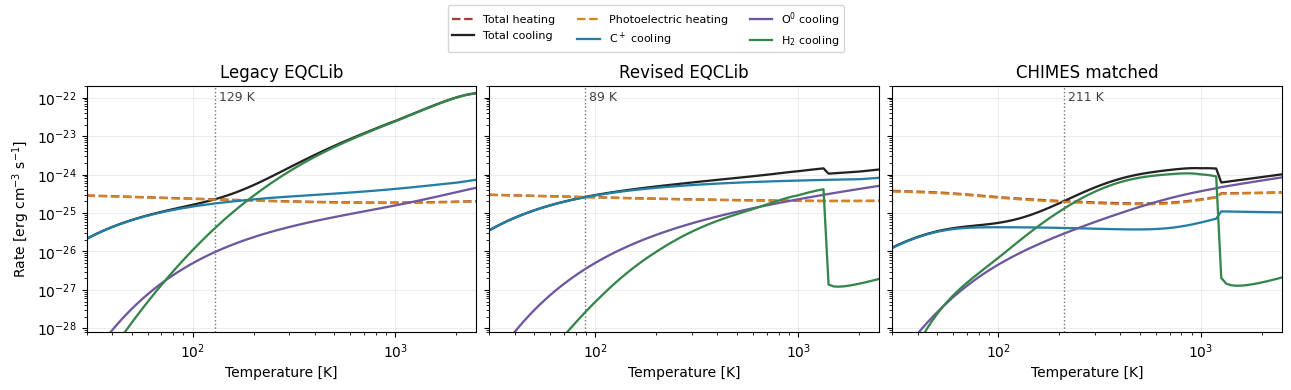

熱収支の数値は $10^{-25}\ \mathrm{erg\,cm^{-3}\,s^{-1}}$ 単位です。

| T [K] | モデル | H₂ 分率 | H I 分率 | 全加熱 | 全冷却 | 正味加熱 | 光電加熱 | [C II] | [O I] | H₂ 冷却 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 89 | 旧 EQCLib | 0.816 | 0.184 | 2.41 | 1.43 | 0.984 | 2.37 | 1.33 | 0.0344 | 0.056 |
| 89 | 現行 EQCLib | 0.03861 | 0.961 | 2.6 | 2.61 | -0.00445 | 2.57 | 2.56 | 0.0349 | 0.00262 |
| 89 | CHIMES matched | 0.4818 | 0.518 | 2.73 | 0.511 | 2.22 | 2.63 | 0.426 | 0.0312 | 0.0422 |
| 129 | 旧 EQCLib | 0.8258 | 0.174 | 2.27 | 2.28 | -0.00915 | 2.23 | 1.77 | 0.0967 | 0.405 |
| 129 | 現行 EQCLib | 0.04341 | 0.956 | 2.49 | 3.64 | -1.15 | 2.45 | 3.51 | 0.103 | 0.0174 |
| 129 | CHIMES matched | 0.472 | 0.528 | 2.36 | 0.739 | 1.62 | 2.26 | 0.424 | 0.0936 | 0.201 |
| 211 | 旧 EQCLib | 0.8265 | 0.174 | 2.11 | 6.05 | -3.94 | 2.07 | 2.32 | 0.258 | 3.47 |
| 211 | 現行 EQCLib | 0.04375 | 0.956 | 2.35 | 5.07 | -2.72 | 2.32 | 4.64 | 0.3 | 0.118 |
| 211 | CHIMES matched | 0.4309 | 0.569 | 2.03 | 2.04 | -0.00272 | 1.94 | 0.407 | 0.292 | 1.3 |

In [15]:
thermal_terms_plot = (
    ("heat", "Total heating", "#a14234", "--"),
    ("cool", "Total cooling", "#222222", "-"),
    ("heat_pe", "Photoelectric heating", "#d28525", "--"),
    ("cool_cii", r"C$^+$ cooling", "#237ea5", "-"),
    ("cool_oi", r"O$^0$ cooling", "#6f57a0", "-"),
    ("H2", r"H$_2$ cooling", "#35854c", "-"),
)
fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.8), sharey=True, layout="constrained")
fixed_rows = []
for axis, model in zip(axes, thermal_models):
    rows = thermal_slice(thermal_native[model], 10.)
    valid = rows["status"] == 0
    for field, label, color, ls in thermal_terms_plot:
        values = rows["cool_h2"] + rows["cool_h2_diss"] if field == "H2" else rows[field]
        axis.plot(rows["T"], np.where(valid & (values > 0), values, np.nan),
                  color=color, ls=ls, lw=1.65, label=label)
    for root in thermal_grid_roots(rows):
        axis.axvline(root, color="0.45", ls=":", lw=1)
        axis.text(root, .98, f" {root:.0f} K", transform=axis.get_xaxis_transform(),
                  va="top", color="0.26", fontsize=9)
    axis.set(xscale="log", yscale="log", xlim=(30,2500), ylim=(8e-29,2e-22),
             title=("Legacy EQCLib", "Revised EQCLib", "CHIMES matched")[thermal_models.index(model)],
             xlabel="Temperature [K]")
    axis.grid(alpha=.22)
    for T in (89.,129.,211.):
        r = thermal_point(rows,T)
        if r is not None:
            values = (r["heat"], r["cool"], r["heat"]-r["cool"], r["heat_pe"], r["cool_cii"],
                      r["cool_oi"], r["cool_h2"]+r["cool_h2_diss"])
            fixed_rows.append((f"{T:g}",thermal_names[model],f"{r['fH2']:.4g}",f"{r['xHI']:.3f}",
                               *(f"{v/1e-25:.3g}" for v in values)))
axes[0].set_ylabel(r"Rate [erg cm$^{-3}$ s$^{-1}$]")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=8)
show_figure(fig)
display(Markdown(r"熱収支の数値は $10^{-25}\ \mathrm{erg\,cm^{-3}\,s^{-1}}$ 単位です。"))
markdown_table(("T [K]", "モデル", "H₂ 分率", "H I 分率", "全加熱", "全冷却",
                "正味加熱", "光電加熱", "[C II]", "[O I]", "H₂ 冷却"),
               sorted(fixed_rows,key=lambda r:(float(r[0]), list(thermal_names.values()).index(r[1]))))

### 旧処方から現行処方への変化

同じ温度 129 K で、「現行 EQCLib の正味加熱 − 旧 EQCLib の正味加熱」を過程ごとに分けます。正の値は加熱を増やすか冷却を減らす変化、負の値はその逆です。各密度で旧処方の全加熱を尺度に使います。

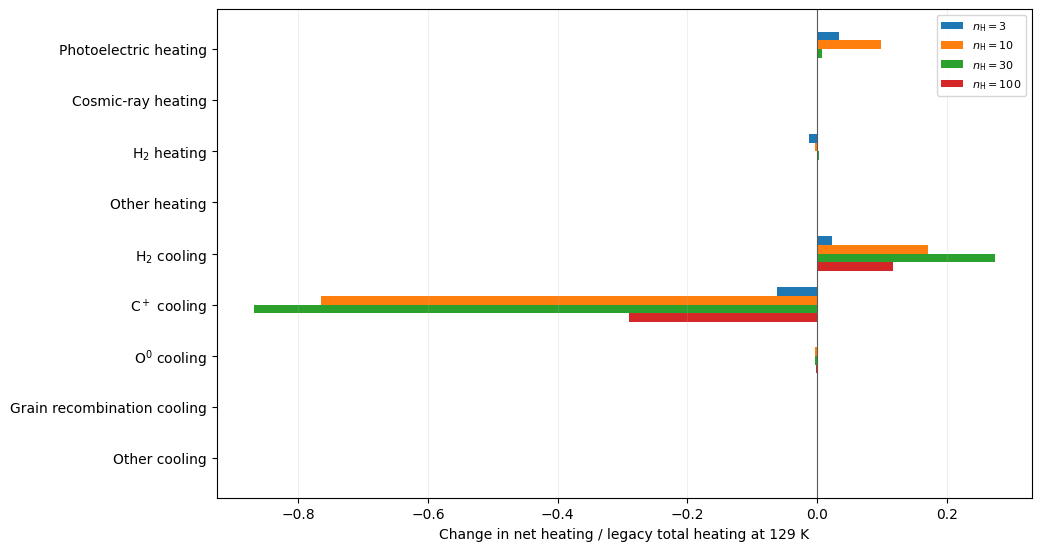

各モデル自身の熱平衡での主要項の割合です。加熱項の分母は全加熱、冷却項の分母は全冷却です。

| nH [cm⁻³] | モデル | 熱平衡 [K] | H₂ 分率 | 光電加熱 | 宇宙線加熱 | [C II] | [O I] | H₂ 回転振動 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 3 | 旧 EQCLib | 227.5 | 0.174 | 97% | 2% | 76% | 5% | 19% |
| 3 | 現行 EQCLib | 286.2 | 3.72e-06 | 98% | 2% | 91% | 8% | 0% |
| 3 | CHIMES matched | 1491.0 | 9.26e-07 | 97% | 3% | 23% | 67% | 0% |
| 10 | 旧 EQCLib | 128.7 | 0.826 | 98% | 1% | 78% | 4% | 18% |
| 10 | 現行 EQCLib | 88.9 | 0.0386 | 99% | 1% | 98% | 1% | 0% |
| 10 | CHIMES matched | 210.9 | 0.431 | 95% | 3% | 20% | 14% | 64% |
| 30 | 旧 EQCLib | 74.7 | 0.972 | 99% | 1% | 95% | 2% | 2% |
| 30 | 現行 EQCLib | 56.3 | 0.552 | 99% | 1% | 99% | 1% | 0% |
| 30 | CHIMES matched | 142.6 | 0.901 | 97% | 2% | 35% | 2% | 62% |
| 100 | 旧 EQCLib | 33.5 | 0.997 | 99% | 1% | 100% | 0% | 0% |
| 100 | 現行 EQCLib | 32.9 | 0.956 | 99% | 1% | 100% | 0% | 0% |
| 100 | CHIMES matched | 82.1 | 0.983 | 95% | 2% | 90% | 0% | 8% |

In [16]:
term_labels = {
    "PE": "Photoelectric heating", "CR": "Cosmic-ray heating", "H2 heat": r"H$_2$ heating",
    "Other heat": "Other heating", "H2 cool": r"H$_2$ cooling", "CII": r"C$^+$ cooling",
    "OI": r"O$^0$ cooling", "Dust rec.": "Grain recombination cooling", "Other cool": "Other cooling",
}
changes = {}
for nh in thermal_densities:
    old = thermal_point(thermal_slice(thermal_native["legacy"],nh),129.)
    new = thermal_point(thermal_slice(thermal_native["eqclib"],nh),129.)
    if old is None or new is None:
        continue
    a, b = signed_thermal_terms(old), signed_thermal_terms(new)
    changes[nh] = {term:(b[term]-a[term])/old["heat"] for term in a}

fig, axis = plt.subplots(figsize=(10.3, 5.4), layout="constrained")
y = np.arange(len(term_labels))
width = .17
for idx,(nh,terms) in enumerate(changes.items()):
    axis.barh(y+(idx-(len(changes)-1)/2)*width, list(terms.values()), height=width,
              label=rf"$n_{{\rm H}}={nh:g}$")
axis.axvline(0,color="0.35",lw=.8)
axis.set(yticks=y, yticklabels=list(term_labels.values()),
         xlabel="Change in net heating / legacy total heating at 129 K")
axis.invert_yaxis()
axis.grid(axis="x",alpha=.2)
axis.legend(fontsize=8)
show_figure(fig)

root_budgets = []
for nh in thermal_densities:
    for model in thermal_models:
        rows = thermal_slice(thermal_native[model],nh)
        for root in thermal_grid_roots(rows):
            vals = thermal_root_rates(rows,root)
            root_budgets.append([
                f"{nh:g}",thermal_names[model],f"{root:.1f}",f"{vals['fH2']:.3g}",
                *(f"{vals[key]/vals['heat']:.0%}" for key in ("heat_pe","heat_cr")),
                *(f"{vals[key]/vals['cool']:.0%}" for key in ("cool_cii","cool_oi","cool_h2")),
            ])
display(Markdown("各モデル自身の熱平衡での主要項の割合です。加熱項の分母は全加熱、冷却項の分母は全冷却です。"))
markdown_table(("nH [cm⁻³]","モデル","熱平衡 [K]","H₂ 分率","光電加熱","宇宙線加熱",
                "[C II]","[O I]","H₂ 回転振動"),root_budgets)

### H I と H₂ の配分を変える試算と、組成をそろえた率の比較

前半の2列は現行の電子・イオン分率と温度を固定した EQCLib で、H I と H₂ の配分だけを旧処方の $f_{\rm H_2}$ に戻す試算です。後半は現行 EQCLib の同じ指定組成を両コードに与えたときの CHIMES / EQCLib 比です。どちらも 129 K を使います。

今回の CHIMES データでは C⁺ 冷却は $T,n_e$ の表を $n(\mathrm{C}^+)n_e$ に掛けます。EQCLib の [C II] は同じ電子励起に加え H I と ortho/para-H₂ の衝突励起を使います。CHIMES の O⁰ は $T,n_e,n(\mathrm{H\,I}),n(\mathrm{H\,II})$ の表です。これらは、今回使った各実装と冷却表の比較です。 [EQCLib の微細構造線](../../../src/FineStructureLines.c) · [CHIMES の冷却率](../../../../Chimes/chimes/src/chimes_cooling.c) · [Richings et al. (2014), §3.1](https://arxiv.org/pdf/1401.4719#page=7)

In [17]:
def thermal_safe_divide(numerator, denominator):
    return float(numerator/denominator) if denominator > 0 else np.nan

shared_table = []
for nh in thermal_densities:
    restored = thermal_point(thermal_slice(thermal_shared["eqclib"],nh,"eq_legacy_h2"),129.)
    eq = thermal_point(thermal_slice(thermal_shared["eqclib"],nh,"eq_state"),129.)
    ch = thermal_point(thermal_slice(thermal_shared["chimes"],nh,"eq_state"),129.)
    if any(r is None for r in (restored,eq,ch)):
        continue
    state_changes = [f"{restored[key]:.3g} → {eq[key]:.3g}" for key in ("fH2","xHI")]
    members = ("heat_pe","cool_cii","cool_oi","cool_h2")
    shared_table.append((f"{nh:g}",*state_changes,
                         display_value(thermal_safe_divide(eq["cool_cii"],restored["cool_cii"])),
                         *(display_value(thermal_safe_divide(ch[key],eq[key])) for key in members)))
markdown_table(("nH [cm⁻³]","H₂ 分率（旧→現）","H I 分率（旧→現）","EQ の [C II] 現 / 旧配分",
                "光電加熱 CH / EQ","[C II] CH / EQ","[O I] CH / EQ","H₂ 回転振動 CH / EQ"),
               shared_table)

pe_details = []
for T in (89.,129.,211.):
    a = thermal_point(thermal_slice(thermal_shared["eqclib"],10.,"eq_state"),T)
    b = thermal_point(thermal_slice(thermal_shared["chimes"],10.,"eq_state"),T)
    if a is None or b is None:
        continue
    pe_details.append([f"{T:g}",f"{a['xe']:.3g}",
        *(f"{a[key]:.3g} / {b[key]:.3g}" for key in ("pe_g0","pe_psi","heat_pe"))])
display(Markdown(r"$n_{\rm H}=10\ \mathrm{cm^{-3}}$、現行 EQCLib の共通組成で測った光電加熱の入力です。各セルは EQCLib / CHIMES の順です。"))
markdown_table(("T [K]","共通の電子分率","減光後 $G_0$",r"帯電パラメータ $\Psi$",
                "光電加熱 [erg cm⁻³ s⁻¹]"),pe_details)

cii_details = []
for T in (89.,129.,211.):
    a = thermal_point(thermal_slice(thermal_shared["eqclib"],10.,"chimes_state"),T)
    b = thermal_point(thermal_slice(thermal_shared["chimes"],10.,"chimes_state"),T)
    if a is None or b is None:
        continue
    cii_details.append([f"{T:g}",f"{a['xHI']:.3g}",f"{a['xe']:.3g}",
                        *(f"{rate/1e-25:.3g}" for rate in (a["cool_cii"],a["cool_cii_e_only"],b["cool_cii"]))])
display(Markdown(
    "CHIMES の主要な平衡組成を両コードに与え、電子衝突と中性粒子衝突の影響を照合します。"
    "「EQ 電子のみ」は同じ電子数密度と C⁺ 密度で [C II] の H I・H₂ 衝突項をゼロにした診断です。"
    "冷却率は $10^{-25}\\ \\mathrm{erg\\,cm^{-3}\\,s^{-1}}$ 単位です。"
))
markdown_table(("T [K]","H I 分率","電子分率","EQ 全衝突","EQ 電子のみ","CHIMES"),cii_details)

| nH [cm⁻³] | H₂ 分率（旧→現） | H I 分率（旧→現） | EQ の [C II] 現 / 旧配分 | 光電加熱 CH / EQ | [C II] CH / EQ | [O I] CH / EQ | H₂ 回転振動 CH / EQ |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 3 | 0.175 → 4.13e-06 | 0.824 → 1 | 1.1 | 0.91 | 0.225 | 1.71 | 0.969 |
| 10 | 0.826 → 0.0434 | 0.174 → 0.956 | 1.86 | 0.985 | 0.137 | 1.64 | 0.958 |
| 30 | 0.975 → 0.613 | 0.0252 → 0.387 | 1.53 | 1.14 | 0.16 | 0.697 | 0.886 |
| 100 | 0.998 → 0.969 | 0.00196 → 0.031 | 1.04 | 1.45 | 0.236 | 0.0597 | 0.656 |

$n_{\rm H}=10\ \mathrm{cm^{-3}}$、現行 EQCLib の共通組成で測った光電加熱の入力です。各セルは EQCLib / CHIMES の順です。

| T [K] | 共通の電子分率 | 減光後 $G_0$ | 帯電パラメータ $\Psi$ | 光電加熱 [erg cm⁻³ s⁻¹] |
| --- | ---: | ---: | ---: | ---: |
| 89 | 0.000427 | 1.11 / 1.2 | 2.46e+03 / 5.3e+03 | 2.57e-25 / 2.57e-25 |
| 129 | 0.000445 | 1.11 / 1.2 | 2.84e+03 / 6.11e+03 | 2.45e-25 / 2.42e-25 |
| 211 | 0.000474 | 1.11 / 1.2 | 3.41e+03 / 7.34e+03 | 2.32e-25 / 2.24e-25 |

CHIMES の主要な平衡組成を両コードに与え、電子衝突と中性粒子衝突の影響を照合します。「EQ 電子のみ」は同じ電子数密度と C⁺ 密度で [C II] の H I・H₂ 衝突項をゼロにした診断です。冷却率は $10^{-25}\ \mathrm{erg\,cm^{-3}\,s^{-1}}$ 単位です。

| T [K] | H I 分率 | 電子分率 | EQ 全衝突 | EQ 電子のみ | CHIMES |
| --- | ---: | ---: | ---: | ---: | ---: |
| 89 | 0.518 | 0.000448 | 1.93 | 0.5 | 0.426 |
| 129 | 0.528 | 0.000391 | 2.55 | 0.499 | 0.424 |
| 211 | 0.569 | 0.000365 | 3.42 | 0.48 | 0.407 |

### 一項ずつ置き換えたときの熱平衡

固定温度の現行 EQCLib の全熱収支を出発点に、一度に一項の率だけを置き換え、温度依存性から新しい熱平衡を探します。「CHIMES 平衡組成」は CHIMES 自身の固定温度での平衡組成を使った率に置き換えます。「同じ指定組成」は、現行 EQCLib の組成の主要成分を与えた共通状態で測った CHIMES − EQCLib の率の差を加えます。各試算の化学組成は再平衡させないため、移動量の和は全体の温度差に一致する必要はありません。

格子上の成功点で正味加熱が正から負に変わる箇所を、隣接2点の対数温度で補間します。未収束点の両側はつなぎません。複数の安定交点は併記します。

In [18]:
sensitive_terms = ("PE","H2 cool","CII","OI","CR","Dust rec.")
term_names_ja = ("光電加熱","H₂ 冷却","[C II] 冷却","[O I] 冷却","宇宙線加熱","ダスト再結合冷却")

def match_thermal_grid(reference,*others):
    # Preserve every temperature in the reference, including an invalid row if present.
    for other in others:
        np.testing.assert_array_equal(reference["T"],other["T"])

def replacement_roots(ref, difference, valid):
    heat_terms = ("PE","CR","H2 heat","Other heat")
    heat = ref["heat"] + sum(delta for term,delta in difference.items() if term in heat_terms)
    cool = ref["cool"] - sum(delta for term,delta in difference.items() if term not in heat_terms)
    return thermal_net_roots(ref["T"],heat,cool,valid & (heat >= 0) & (cool >= 0))

def all_replacement_roots(ref,left,right,groups):
    match_thermal_grid(ref,left,right)
    valid = (ref["status"] == 0) & (left["status"] == 0) & (right["status"] == 0)
    a,b = signed_thermal_terms(left),signed_thermal_terms(right)
    return [replacement_roots(ref,{term: b[term]-a[term] for term in group},valid) for group in groups]

thermal_sensitivity = []
thermal_revert = []
thermal_combined = []
for nh in thermal_densities:
    eq = thermal_slice(thermal_native["eqclib"],nh)
    old = thermal_slice(thermal_native["legacy"],nh)
    ch = thermal_slice(thermal_native["chimes"],nh)
    be = thermal_slice(thermal_shared["eqclib"],nh,"eq_state")
    bc = thermal_slice(thermal_shared["chimes"],nh,"eq_state")
    roots = thermal_grid_roots(eq)
    for scenario,left,right in (("CHIMES 平衡組成",eq,ch),("同じ指定組成",be,bc)):
        targets = all_replacement_roots(eq,left,right,[(term,) for term in sensitive_terms])
        thermal_sensitivity.append((f"{nh:g}",scenario,root_text(roots),*map(root_text,targets)))

    targets = all_replacement_roots(eq,eq,old,[(term,) for term in ("PE","H2 cool","CII","OI")])
    bh = thermal_slice(thermal_shared["eqclib"],nh,"eq_legacy_h2")
    targets.extend(all_replacement_roots(eq,be,bh,(("CII",),)))
    thermal_revert.append((f"{nh:g}",root_text(roots),*map(root_text,targets)))
    combined = []
    for source,groups in ((old, (("CII","H2 cool"),("CII","H2 cool","PE"))),
                          (ch, (("CII","H2 cool"),("CII","H2 cool","OI","PE")))):
        combined.extend(all_replacement_roots(eq,eq,source,groups))
    thermal_combined.append((f"{nh:g}", *map(root_text,combined)))

markdown_table(("nH [cm⁻³]","置換する率","現行 [K]",*(name+" [K]" for name in term_names_ja)),
               thermal_sensitivity)
display(Markdown("旧 EQCLib の率に一項ずつ戻した場合も同じ方法で求めます。最終列は H I・H₂ の配分だけを戻して計算した [C II] の差を使います。"))
markdown_table(("nH [cm⁻³]","現行 [K]",*(name+" [K]" for name in term_names_ja[:4]),
                "旧 H I・H₂ 配分での [C II] [K]"),thermal_revert)
display(Markdown("複数の主要項を同時に置き換えた場合の熱平衡温度です。"))
markdown_table(("nH [cm⁻³]","旧 [C II]・H₂ [K]","旧 [C II]・H₂・光電 [K]",
                "CH [C II]・H₂ [K]","CH [C II]・H₂・[O I]・光電 [K]"), thermal_combined)

| nH [cm⁻³] | 置換する率 | 現行 [K] | 光電加熱 [K] | H₂ 冷却 [K] | [C II] 冷却 [K] | [O I] 冷却 [K] | 宇宙線加熱 [K] | ダスト再結合冷却 [K] |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 3 | CHIMES 平衡組成 | 286 | 479 | 286 | 1.84e+03 | 261 | 296 | 285 |
| 3 | 同じ指定組成 | 286 | 234 | 286 | 2.34e+03 | 261 | 296 | 286 |
| 10 | CHIMES 平衡組成 | 88.9 | 90.3 | 87.8 | 458 | 89 | 90.2 | 88.9 |
| 10 | 同じ指定組成 | 88.9 | 88.8 | 88.9 | 436 | 88.2 | 90.1 | 88.9 |
| 30 | CHIMES 平衡組成 | 56.3 | 63.4 | 56.2 | 142 | 56.5 | 56.9 | 56.3 |
| 30 | 同じ指定組成 | 56.3 | 62.7 | 56.3 | 142 | 56.4 | 56.9 | 56.3 |
| 100 | CHIMES 平衡組成 | 32.9 | 39 | 32.9 | 54.3 | 32.9 | 33.2 | 32.9 |
| 100 | 同じ指定組成 | 32.9 | 38.9 | 32.9 | 56.2 | 32.9 | 33.2 | 32.9 |

旧 EQCLib の率に一項ずつ戻した場合も同じ方法で求めます。最終列は H I・H₂ の配分だけを戻して計算した [C II] の差を使います。

| nH [cm⁻³] | 現行 [K] | 光電加熱 [K] | H₂ 冷却 [K] | [C II] 冷却 [K] | [O I] 冷却 [K] | 旧 H I・H₂ 配分での [C II] [K] |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 3 | 286 | 268 | 213 | 337 | 288 | 331 |
| 10 | 88.9 | 83.2 | 87.5 | 175 | 88.9 | 165 |
| 30 | 56.3 | 56.1 | 56.2 | 76 | 56.3 | 75.5 |
| 100 | 32.9 | 32.9 | 32.9 | 33.5 | 32.9 | 33.5 |

複数の主要項を同時に置き換えた場合の熱平衡温度です。

| nH [cm⁻³] | 旧 [C II]・H₂ [K] | 旧 [C II]・H₂・光電 [K] | CH [C II]・H₂ [K] | CH [C II]・H₂・[O I]・光電 [K] |
| --- | ---: | ---: | ---: | ---: |
| 3 | 232 | 224 | 1.84e+03 | 1.62e+03 |
| 10 | 136 | 128 | 224 | 210 |
| 30 | 75.2 | 74.9 | 132 | 142 |
| 100 | 33.5 | 33.5 | 54.5 | 79.7 |

### 89 K まで下がった理由と、密度による違い

- **旧処方から現行処方への変化** — $n_{\rm H}=10\ {\rm cm^{-3}}$・129 K では、H₂ 分率が 0.826 から 0.0434 へ低下し、H I 分率が 0.174 から 0.956 へ上昇します。H₂ 冷却は $3.88\times10^{-26}\ \mathrm{erg\,cm^{-3}\,s^{-1}}$ 減り、[C II] 冷却は $1.74\times10^{-25}$ 増えます。光電加熱の増加 $2.24\times10^{-26}$ も合わせると、正味冷却は増加します。電子と金属イオンの分率を現行値に固定して H I・H₂ の配分だけを旧に戻すと、[C II] の増分の約94%が消えます。[C II]・H₂ 冷却と光電加熱をまとめて旧処方の率に置き換えると、熱平衡温度は 89 K から約128 K に戻ります。
- **CHIMES の 211 K との差** — 89 K の光電加熱は現行 EQCLib と CHIMES で $2.57$ と $2.63$、[C II] 冷却は $2.56$ と $0.426$ です（いずれも $10^{-25}\ \mathrm{erg\,cm^{-3}\,s^{-1}}$ 単位）。両コードに CHIMES の主要な平衡組成を与えた試算では、EQCLib の全衝突冷却 $1.93\times10^{-25}$ が電子衝突のみで $0.500\times10^{-25}$ となり、CHIMES の $0.426\times10^{-25}$ に近づきます。現行 EQCLib の [C II] だけを CHIMES の率に置き換えると平衡は約458 K に上がります。CHIMES 自身の平衡 211 K では H₂ が全冷却の約64%を占めるため、暖かい側まで比べるには [C II] と H₂ の両方の率が効きます。[C II]・H₂・[O I] 冷却と光電加熱を CHIMES の各温度での率に置き換えると、約210 K で熱平衡に達します。
- **密度による違い** — $3\ {\rm cm^{-3}}$ では旧 EQCLib の平衡付近で H₂ 冷却が全体の約19%を占め、現行処方でこれが減ると平衡は約228 K から286 Kへ上昇します。$30\ {\rm cm^{-3}}$ では [C II] 増加に伴い約75 K から56 K に低下します。$100\ {\rm cm^{-3}}$ では現行・旧ともに H₂ 分率が高く、約33 K にとどまります。CHIMES の主な冷却過程は $3\ {\rm cm^{-3}}$ で [O I]、$10$ と $30\ {\rm cm^{-3}}$ で H₂、$100\ {\rm cm^{-3}}$ で [C II] です。

固定温度計算は EQCLib の旧・現行とも各432点、CHIMES は432点中415点が成功しました。共通組成の診断では各コード1279点を評価しました。本節の現行 EQCLib は最適化後のソルバーで計算しています。